# Итоговый проект Data Analyst

## Анализ эффективности маркетинговых кампаний магазина спортивных товаров

### Цель проекта

На основе данных о клиентах и их покупках:

- подготовить и очистить данные;
- восстановить пропущенный пол клиентов с помощью модели бинарной классификации;
- оценить эффективность первой маркетинговой кампании с помощью A/B-теста;
- провести кластеризацию клиентской базы;
- построить модель склонности клиента к покупке;
- сформулировать бизнес-рекомендации.

In [1]:
import sqlite3
import re
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
DB_PATH = "shop_database.db"

conn = sqlite3.connect(DB_PATH)

tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table'
    """,
    conn
)

tables

,name
0,purchases
1,personal_data_coeffs
2,personal_data


In [3]:
purchases = pd.read_sql_query(
    "SELECT * FROM purchases",
    conn
)

personal_data = pd.read_sql_query(
    "SELECT * FROM personal_data",
    conn
)

personal_coeffs = pd.read_sql_query(
    "SELECT * FROM personal_data_coeffs",
    conn
)

In [4]:
print("purchases:", purchases.shape)
print("personal_data:", personal_data.shape)
print("personal_coeffs:", personal_coeffs.shape)

purchases: (786260, 7)
personal_data: (89241, 6)
personal_coeffs: (104989, 5)


In [5]:
display(purchases.head())
display(personal_data.head())
display(personal_coeffs.head())

,id,product,colour,cost,product_sex,base_sale,dt
0,0,"Велосипед горный женский Stern Mira 2.0 26""",белый/синий,13599,0.0,1,7
1,0,Стол Outventure,зелёный,1499,NaN,0,37
2,0,Набор Outventure: стол + 4 стула,бежевый,4799,NaN,0,37
3,3,Бутсы мужские GSD Astro,белый,1599,1.0,0,13
4,3,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мультицвет,7199,NaN,0,27


,id,gender,age,education,city,country
0,0,0,36,среднее,1201,32
1,4,0,35,среднее,1134,32
2,6,1,52,среднее,1188,32
3,7,0,37,среднее,1198,32
4,9,0,48,среднее,1134,32


,id,lbt_coef,ac_coef,sm_coef,personal_coef
0,0,5.078678,-0.307147,0.959027,0.5072
1,3,7.764766,-0.030225,0.794720,0.4304
2,4,4.569378,0.063693,0.820892,0.5072
3,6,8.150379,0.075200,0.836140,0.4304
4,7,5.188231,-0.000134,0.944113,0.5072


In [6]:
print("PURCHASES")
purchases.info()

print("\nPERSONAL DATA")
personal_data.info()

print("\nPERSONAL COEFFS")
personal_coeffs.info()

PURCHASES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 786260 entries, 0 to 786259
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   id           786260 non-null  int64  
 1   product      786260 non-null  object 
 2   colour       666736 non-null  object 
 3   cost         786260 non-null  int64  
 4   product_sex  471548 non-null  float64
 5   base_sale    786260 non-null  int64  
 6   dt           786260 non-null  int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 42.0+ MB

PERSONAL DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89241 entries, 0 to 89240
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         89241 non-null  int64 
 1   gender     89241 non-null  int64 
 2   age        89241 non-null  int64 
 3   education  89241 non-null  object
 4   city       89241 non-null  int64 
 5   country    89241 non-null  in

In [7]:
def missing_report(df):
    result = pd.DataFrame({
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100
    })

    return result[result["missing"] > 0].sort_values(
        "missing_pct",
        ascending=False
    )

In [8]:
display(missing_report(purchases))
display(missing_report(personal_data))
display(missing_report(personal_coeffs))

,missing,missing_pct
product_sex,314712,40.026454
colour,119524,15.201587


,missing,missing_pct


,missing,missing_pct


In [9]:
lost_personal_data = pd.read_csv(
    "personal_data.csv.gz"
)

lost_personal_data.head()

,id,age,education,city,country
0,101492,32,среднее,1188,32
1,42690,20,высшее,1134,32
2,113001,27,среднее,1187,32
3,163654,49,высшее,1160,32
4,69523,44,среднее,1137,32


In [10]:
lost_personal_data.shape

(15748, 5)

In [11]:
lost_personal_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15748 entries, 0 to 15747
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         15748 non-null  int64 
 1   age        15748 non-null  int64 
 2   education  15748 non-null  object
 3   city       15748 non-null  int64 
 4   country    15748 non-null  int64 
dtypes: int64(4), object(1)
memory usage: 615.3+ KB


In [12]:
intersection = set(personal_data["id"]) & set(lost_personal_data["id"])

len(intersection)

0

In [13]:
len(personal_data) + len(lost_personal_data)

104989

In [14]:
personal_coeffs["id"].nunique()

104989

### Первичный вывод

В базе содержится 104 989 уникальных клиентов.

Персональные данные разделены на две части:

- 89 241 клиент с известным значением пола;
- 15 748 клиентов, для которых поле `gender` было утеряно.

ID двух выборок не пересекаются. После восстановления пола обе части можно будет объединить в единую клиентскую таблицу.

В таблице покупок обнаружены пропуски в признаках `colour` и `product_sex`. Их обработка будет выполнена на этапе предобработки.

Следующим этапом необходимо проверить уникальность ID, дубликаты, значения категориальных признаков и выполнить обязательную фильтрацию клиентов по `country = 32`.

In [15]:
print("personal_data")
print("Полных дубликатов:", personal_data.duplicated().sum())
print("Дубликатов id:", personal_data["id"].duplicated().sum())

print("\nlost_personal_data")
print("Полных дубликатов:", lost_personal_data.duplicated().sum())
print("Дубликатов id:", lost_personal_data["id"].duplicated().sum())

print("\npersonal_coeffs")
print("Дубликатов id:", personal_coeffs["id"].duplicated().sum())

personal_data
Полных дубликатов: 0
Дубликатов id: 0

lost_personal_data
Полных дубликатов: 0
Дубликатов id: 0

personal_coeffs
Дубликатов id: 0


In [16]:
print("personal_data:")
display(personal_data["country"].value_counts().head(10))

print("\nlost_personal_data:")
display(lost_personal_data["country"].value_counts().head(10))

personal_data:


country
32    88786
35      255
38       72
5        30
0        29
37        9
39        8
2         8
33        5
7         4
Name: count, dtype: int64


lost_personal_data:


country
32    15651
35       52
38       16
5         5
0         4
2         4
37        3
39        2
7         2
48        2
Name: count, dtype: int64

In [17]:
personal_data_32 = personal_data[
    personal_data["country"] == 32
].copy()

lost_personal_data_32 = lost_personal_data[
    lost_personal_data["country"] == 32
].copy()

print("Известный gender:", personal_data_32.shape)
print("Утерянный gender:", lost_personal_data_32.shape)

Известный gender: (88786, 6)
Утерянный gender: (15651, 5)


In [18]:
len(personal_data_32) + len(lost_personal_data_32)

104437

### Фильтрация по стране

В соответствии с условием проекта дальнейший анализ проводится только для клиентов страны с кодом `32`.

После фильтрации осталось:

- 88 786 клиентов с известным полом;
- 15 651 клиент с утерянным полом;
- всего 104 437 клиентов.

Записи остальных стран исключены из дальнейшего анализа.

In [19]:
personal_data_32["gender"].value_counts()

gender
1    50910
0    37876
Name: count, dtype: int64

In [20]:
personal_data_32["gender"].value_counts(normalize=True).round(4)

gender
1    0.5734
0    0.4266
Name: proportion, dtype: float64

In [21]:
personal_data_32["age"].describe()

count    88786.000000
mean        38.029160
std         12.295099
min          5.000000
25%         30.000000
50%         38.000000
75%         46.000000
max         77.000000
Name: age, dtype: float64

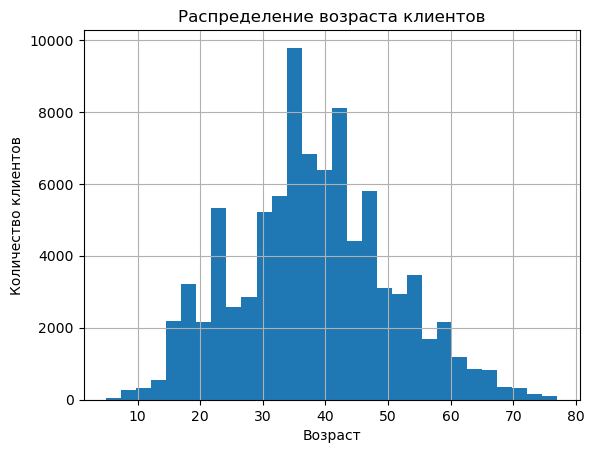

In [22]:
personal_data_32["age"].hist(bins=30)

plt.title("Распределение возраста клиентов")
plt.xlabel("Возраст")
plt.ylabel("Количество клиентов")
plt.show()

In [23]:
personal_data_32["education"].value_counts(dropna=False)

education
среднее    69539
высшее     19247
Name: count, dtype: int64

In [24]:
lost_personal_data_32["education"].value_counts(dropna=False)

education
среднее    12235
высшее      3416
Name: count, dtype: int64

In [25]:
print(
    "Количество уникальных городов:",
    personal_data_32["city"].nunique()
)

display(
    personal_data_32["city"]
    .value_counts()
    .head(15)
)

Количество уникальных городов: 607


city
1134    22851
1188    10525
1157     3527
1178     3058
1167     2647
1204     2645
1177     2591
1187     2114
1201     1906
1183     1738
1162     1673
1185     1368
1156     1342
1179     1323
1168     1211
Name: count, dtype: int64

In [26]:
personal_coef = personal_coeffs[
    ["id", "personal_coef"]
].copy()

In [27]:
train_personal = personal_data_32.merge(
    personal_coef,
    on="id",
    how="left"
)

predict_personal = lost_personal_data_32.merge(
    personal_coef,
    on="id",
    how="left"
)

In [28]:
print("train_personal:", train_personal.shape)
print("predict_personal:", predict_personal.shape)

print(
    "Пропуски personal_coef train:",
    train_personal["personal_coef"].isna().sum()
)

print(
    "Пропуски personal_coef predict:",
    predict_personal["personal_coef"].isna().sum()
)

train_personal: (88786, 7)
predict_personal: (15651, 6)
Пропуски personal_coef train: 0
Пропуски personal_coef predict: 0


In [29]:
display(train_personal.head())

,id,gender,age,education,city,country,personal_coef
0,0,0,36,среднее,1201,32,0.5072
1,4,0,35,среднее,1134,32,0.5072
2,6,1,52,среднее,1188,32,0.4304
3,7,0,37,среднее,1198,32,0.5072
4,9,0,48,среднее,1134,32,0.5072


In [30]:
display(predict_personal.head())

,id,age,education,city,country,personal_coef
0,101492,32,среднее,1188,32,0.4304
1,42690,20,высшее,1134,32,0.4688
2,113001,27,среднее,1187,32,0.4304
3,163654,49,высшее,1160,32,0.5584
4,69523,44,среднее,1137,32,0.5072


In [31]:
FEATURES = [
    "age",
    "education",
    "city",
    "personal_coef"
]

TARGET = "gender"

X = train_personal[FEATURES].copy()
y = train_personal[TARGET].copy()

X_predict = predict_personal[FEATURES].copy()

In [32]:
print("X:", X.shape)
print("y:", y.shape)
print("X_predict:", X_predict.shape)

display(X.head())

X: (88786, 4)
y: (88786,)
X_predict: (15651, 4)


,age,education,city,personal_coef
0,36,среднее,1201,0.5072
1,35,среднее,1134,0.5072
2,52,среднее,1188,0.4304
3,37,среднее,1198,0.5072
4,48,среднее,1134,0.5072


### Подготовка данных к восстановлению пола клиентов

Для обучения модели использованы клиенты страны `32`, для которых значение `gender` известно.

В качестве признаков выбраны:

- `age` - возраст клиента;
- `education` - уровень образования;
- `city` - город;
- `personal_coef` - персональный коэффициент клиента.

Признак `id` исключён как технический идентификатор.

Признак `country` не используется, поскольку после фильтрации принимает одно значение (`32`) для всех наблюдений.

Целевая переменная - `gender`.

Обучающая выборка содержит 88 786 клиентов, а предсказать пол необходимо для 15 651 клиента.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nРаспределение target в train:")
print(y_train.value_counts(normalize=True).round(4))

print("\nРаспределение target в test:")
print(y_test.value_counts(normalize=True).round(4))

X_train: (71028, 4)
X_test: (17758, 4)

Распределение target в train:
gender
1    0.5734
0    0.4266
Name: proportion, dtype: float64

Распределение target в test:
gender
1    0.5734
0    0.4266
Name: proportion, dtype: float64


In [34]:
numeric_features = [
    "age",
    "personal_coef"
]

categorical_features = [
    "education",
    "city"
]

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [36]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [37]:
from sklearn.linear_model import LogisticRegression

logreg_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state= 42
            )
        )
    ]
)

In [38]:
logreg_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'personal_coef']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['education', 'city'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred_logreg = logreg_model.predict(X_test)

print(
    "Accuracy:",
    round(
        accuracy_score(y_test, y_pred_logreg),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(y_test, y_pred_logreg),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(y_test, y_pred_logreg),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(y_test, y_pred_logreg),
        4
    )
)

Accuracy: 0.9791
Precision: 0.9648
Recall: 1.0
F1: 0.9821


In [40]:
print(
    classification_report(
        y_test,
        y_pred_logreg
    )
)

              precision    recall  f1-score   support

           0       1.00      0.95      0.97      7576
           1       0.96      1.00      0.98     10182

    accuracy                           0.98     17758
   macro avg       0.98      0.98      0.98     17758
weighted avg       0.98      0.98      0.98     17758



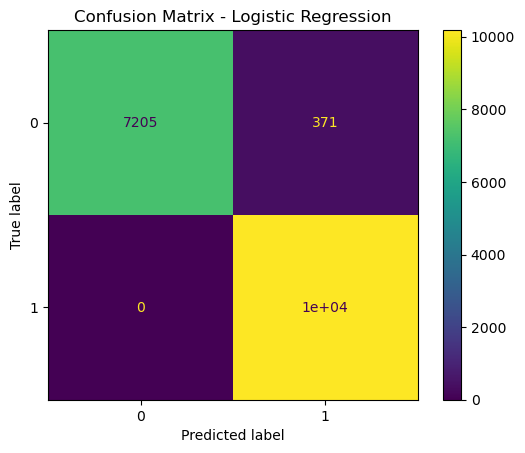

In [41]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logreg
)

plt.title(
    "Confusion Matrix - Logistic Regression"
)

plt.show()

In [42]:
majority_class = y_train.mode()[0]

y_pred_dummy = np.full(
    shape=len(y_test),
    fill_value=majority_class
)

print(
    "Dummy F1:",
    round(
        f1_score(y_test, y_pred_dummy),
        4
    )
)

Dummy F1: 0.7288


In [43]:
print(
    "Dummy F1:",
    round(
        f1_score(y_test, y_pred_dummy),
        4
    )
)

print(
    "Logistic Regression F1:",
    round(
        f1_score(y_test, y_pred_logreg),
        4
    )
)

Dummy F1: 0.7288
Logistic Regression F1: 0.9821


In [44]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [45]:
rf_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'personal_coef']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['education', 'city'])])),
                ('model',
                 RandomForestClassifier(min_samples_leaf=2, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [46]:
y_pred_rf = rf_model.predict(X_test)

In [47]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

print(
    "Random Forest F1:",
    round(
        f1_score(y_test, y_pred_rf),
        4
    )
)

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      7576
           1       0.99      1.00      1.00     10182

    accuracy                           1.00     17758
   macro avg       1.00      1.00      1.00     17758
weighted avg       1.00      1.00      1.00     17758

Random Forest F1: 0.9965


In [48]:
model_results = pd.DataFrame({
    "model": [
        "Dummy",
        "Logistic Regression",
        "Random Forest"
    ],
    "accuracy": [
        accuracy_score(
            y_test,
            y_pred_dummy
        ),
        accuracy_score(
            y_test,
            y_pred_logreg
        ),
        accuracy_score(
            y_test,
            y_pred_rf
        )
    ],
    "precision": [
        precision_score(
            y_test,
            y_pred_dummy,
            zero_division=0
        ),
        precision_score(
            y_test,
            y_pred_logreg
        ),
        precision_score(
            y_test,
            y_pred_rf
        )
    ],
    "recall": [
        recall_score(
            y_test,
            y_pred_dummy
        ),
        recall_score(
            y_test,
            y_pred_logreg
        ),
        recall_score(
            y_test,
            y_pred_rf
        )
    ],
    "f1": [
        f1_score(
            y_test,
            y_pred_dummy
        ),
        f1_score(
            y_test,
            y_pred_logreg
        ),
        f1_score(
            y_test,
            y_pred_rf
        )
    ]
})

model_results.sort_values(
    "f1",
    ascending=False
)

,model,accuracy,precision,recall,f1
2,Random Forest,0.996002,0.993075,1.0,0.996526
1,Logistic Regression,0.979108,0.964844,1.0,0.982108
0,Dummy,0.573375,0.573375,1.0,0.728848


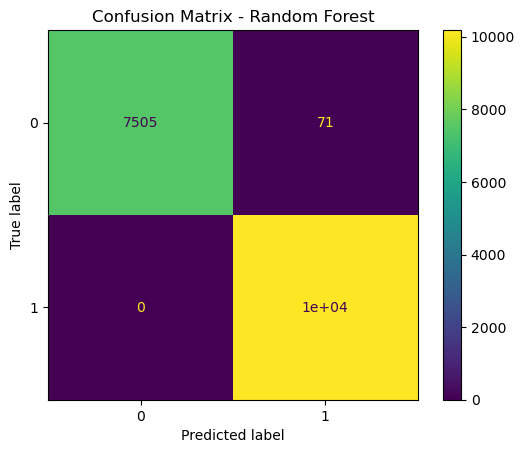

In [49]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf
)

plt.title(
    "Confusion Matrix - Random Forest"
)

plt.show()

In [50]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

cm_rf

array([[ 7505,    71],
       [    0, 10182]])

In [51]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("F1 по фолдам:")
print(cv_scores)

print(
    "\nСредний F1:",
    round(cv_scores.mean(), 4)
)

print(
    "STD F1:",
    round(cv_scores.std(), 4)
)

F1 по фолдам:
[0.99764844 0.99750184 0.9975507  0.9971111  0.99857794]

Средний F1: 0.9977
STD F1: 0.0005


### Проверка устойчивости Random Forest

Для проверки стабильности модели была проведена стратифицированная
5-fold cross-validation.

Среднее значение F1 составило около `0.9977`,
стандартное отклонение - около `0.0005`.

Низкий разброс между фолдами показывает, что высокое качество модели
не связано с удачным случайным разбиением train/test.

По матрице ошибок модель допустила 71 ложноположительную ошибку
и не допустила ни одной ложноотрицательной ошибки.

Таким образом, Random Forest показывает высокое и устойчивое качество
при восстановлении пола клиентов.

In [52]:
FEATURES_NO_COEF = [
    "age",
    "education",
    "city"
]

X_no_coef = train_personal[
    FEATURES_NO_COEF
].copy()

In [53]:
preprocessor_no_coef = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            ["age"]
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            ["education", "city"]
        )
    ]
)

In [54]:
rf_no_coef = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_no_coef
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [55]:
X_train_nc = X_no_coef.loc[X_train.index]
X_test_nc = X_no_coef.loc[X_test.index]

rf_no_coef.fit(
    X_train_nc,
    y_train
)

y_pred_nc = rf_no_coef.predict(
    X_test_nc
)

print(
    "Random Forest без personal_coef F1:",
    round(
        f1_score(
            y_test,
            y_pred_nc
        ),
        4
    )
)

Random Forest без personal_coef F1: 0.689


### Baseline классификации пола

Были протестированы три подхода:

- Dummy-классификатор;
- Logistic Regression;
- Random Forest.

На тестовой выборке лучший результат показал Random Forest:

- Accuracy ≈ 0.9960;
- Precision ≈ 0.9931;
- Recall = 1.0000;
- F1 ≈ 0.9965.

Результат значительно превосходит наивный baseline и Logistic Regression.

Устойчивость результата дополнительно проверена с помощью
5-fold cross-validation, а также отдельно оценён вклад признака
`personal_coef`.

### Влияние `personal_coef`

Для оценки вклада персонального коэффициента была дополнительно обучена
модель Random Forest без признака `personal_coef`.

F1 модели без `personal_coef` составил около `0.689`,
тогда как с использованием коэффициента F1 составляет около `0.9965`,
а средний F1 по 5-fold cross-validation - около `0.9977`.

Таким образом, `personal_coef` является ключевым признаком для восстановления
пола клиентов. Социально-демографические признаки `age`, `education` и `city`
сами по себе обладают значительно меньшей предсказательной способностью.

Поскольку использование `personal_coef` предусмотрено условием проекта,
данный признак оставлен в итоговой модели.

In [56]:
train_personal.groupby("gender")["personal_coef"].describe()

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
0,37876.0,0.503245,0.050498,0.2768,0.5072,0.5072,0.5072,0.5584
1,50910.0,0.426007,0.047574,0.2576,0.4304,0.4304,0.4304,0.4688


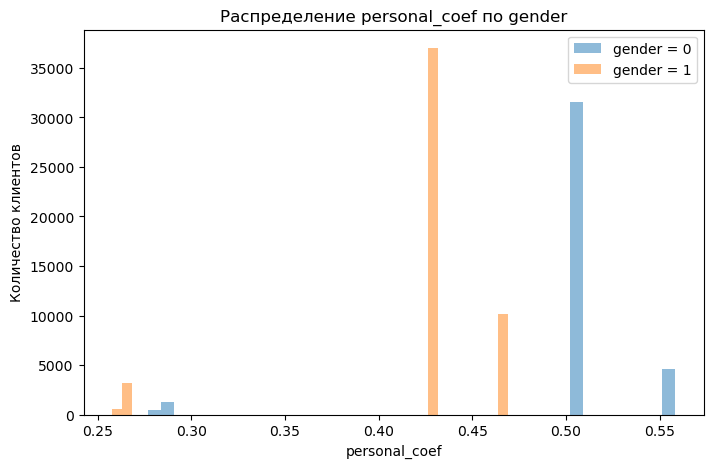

In [57]:
plt.figure(figsize=(8, 5))

for gender_value in sorted(train_personal["gender"].unique()):
    subset = train_personal.loc[
        train_personal["gender"] == gender_value,
        "personal_coef"
    ]

    plt.hist(
        subset,
        bins=40,
        alpha=0.5,
        label=f"gender = {gender_value}"
    )

plt.title("Распределение personal_coef по gender")
plt.xlabel("personal_coef")
plt.ylabel("Количество клиентов")
plt.legend()
plt.show()

In [58]:
rf_final = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_final.fit(
    X,
    y
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'personal_coef']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['education', 'city'])])),
                ('model',
                 RandomForestClassifier(min_samples_leaf=2, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [59]:
gender_pred = rf_final.predict(
    X_predict
)

gender_pred[:20]

array([1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0])

In [60]:
predict_personal["gender"] = gender_pred

In [61]:
predict_personal["gender"].value_counts()

gender
1    8931
0    6720
Name: count, dtype: int64

In [62]:
predict_personal["gender"].value_counts(
    normalize=True
).round(4)

gender
1    0.5706
0    0.4294
Name: proportion, dtype: float64

In [63]:
train_personal["gender_source"] = "original"
predict_personal["gender_source"] = "predicted"

In [64]:
client_columns = [
    "id",
    "gender",
    "age",
    "education",
    "city",
    "country",
    "personal_coef",
    "gender_source"
]

In [65]:
clients = pd.concat(
    [
        train_personal[client_columns],
        predict_personal[client_columns]
    ],
    ignore_index=True
)

In [66]:
print("Размер clients:", clients.shape)
print("Уникальных id:", clients["id"].nunique())
print("Пропусков:\n", clients.isna().sum())

Размер clients: (104437, 8)
Уникальных id: 104437
Пропусков:
 id               0
gender           0
age              0
education        0
city             0
country          0
personal_coef    0
gender_source    0
dtype: int64


In [67]:
print(
    "Распределение источника gender:"
)

print(
    clients["gender_source"].value_counts()
)

Распределение источника gender:
gender_source
original     88786
predicted    15651
Name: count, dtype: int64


In [68]:
print(
    "Страны:",
    clients["country"].nunique()
)

Страны: 1


In [69]:
clients["gender"].value_counts(
    normalize=True
).round(4)

gender
1    0.573
0    0.427
Name: proportion, dtype: float64

In [70]:
clients.to_pickle(
    "clients_clean.pkl"
)

clients.to_csv(
    "clients_clean.csv",
    index=False
)

## Восстановление утерянных персональных данных

Для восстановления признака `gender` была выбрана модель Random Forest.

На тестовой выборке модель показала F1 около `0.9965`.
При 5-fold cross-validation среднее значение F1 составило около `0.9977`
при стандартном отклонении около `0.0005`.

Дополнительный эксперимент показал, что ключевым предиктором является
`personal_coef`: без него F1 снизился примерно до `0.689`.

После проверки качества финальная модель была обучена на всех клиентах
с известным полом и использована для восстановления `gender`
у 15 651 клиента.

После объединения исходных и восстановленных данных получена единая
таблица из 104 437 клиентов страны 32 без пропусков в персональных признаках.

In [71]:
print("Размер purchases:", purchases.shape)
print("Уникальных клиентов:", purchases["id"].nunique())

display(purchases.head())

purchases.info()

Размер purchases: (786260, 7)
Уникальных клиентов: 104989


,id,product,colour,cost,product_sex,base_sale,dt
0,0,"Велосипед горный женский Stern Mira 2.0 26""",белый/синий,13599,0.0,1,7
1,0,Стол Outventure,зелёный,1499,NaN,0,37
2,0,Набор Outventure: стол + 4 стула,бежевый,4799,NaN,0,37
3,3,Бутсы мужские GSD Astro,белый,1599,1.0,0,13
4,3,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мультицвет,7199,NaN,0,27


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 786260 entries, 0 to 786259
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   id           786260 non-null  int64  
 1   product      786260 non-null  object 
 2   colour       666736 non-null  object 
 3   cost         786260 non-null  int64  
 4   product_sex  471548 non-null  float64
 5   base_sale    786260 non-null  int64  
 6   dt           786260 non-null  int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 42.0+ MB


In [72]:
print(
    "Полных дубликатов:",
    purchases.duplicated().sum()
)

Полных дубликатов: 0


In [73]:
missing_purchases = pd.DataFrame({
    "missing": purchases.isna().sum(),
    "missing_pct": (
        purchases.isna().mean() * 100
    ).round(2)
})

display(
    missing_purchases[
        missing_purchases["missing"] > 0
    ]
)

,missing,missing_pct
colour,119524,15.20
product_sex,314712,40.03


In [74]:
display(
    purchases[
        ["cost", "base_sale"]
    ].describe()
)

,cost,base_sale
count,786260.000000,786260.000000
mean,5406.566271,0.356883
std,10394.947580,0.479080
min,-30.000000,0.000000
25%,1499.000000,0.000000
50%,2999.000000,0.000000
75%,5599.000000,1.000000
max,446420.000000,1.000000


In [75]:
print(
    "base_sale:",
    purchases["base_sale"].value_counts(
        dropna=False
    )
)

base_sale: base_sale
0    505657
1    280603
Name: count, dtype: int64


In [76]:
print(
    purchases["dt"].head()
)

print(
    purchases["dt"].dtype
)

0     7
1    37
2    37
3    13
4    27
Name: dt, dtype: int64
int64


In [77]:
display(
    purchases["dt"]
    .value_counts()
    .sort_index()
    .head(20)
)

dt
0     19979
1     18619
2     17962
3     18601
4     18806
5     14389
6     15734
7     20072
8     18017
9     18677
10    21650
11    18611
12    15818
13    18828
14    25630
15    22957
16    18882
17    14077
18    13414
19     9978
Name: count, dtype: int64

In [78]:
print(
    "Уникальных товаров:",
    purchases["product"].nunique()
)

Уникальных товаров: 23145


In [79]:
display(
    purchases["product"]
    .value_counts()
    .head(30)
)

product
Брюки мужские Demix                  4961
Шорты мужские Demix                  4650
Футболка мужская Demix               3644
Лиф женский Joss                     3378
Футболка женская Demix               3252
Брюки мужские Outventure             3132
Купальник женский Joss               2787
Брюки мужские FILA                   2746
Плавки женские Joss                  2585
Брюки женские Outventure             2443
Сабо Crocs Crocband                  2213
Легинсы женские Demix                2175
Брюки женские FILA                   2078
Рюкзак Demix                         1914
Ветровка женская Outventure          1858
Толстовка мужская Demix              1777
Брюки женские Demix                  1767
Футболка мужская Termit              1729
Сумка FILA                           1714
Кресло кемпинговое Outventure        1705
Купальник женский FILA               1683
Солнцезащитные очки Kappa            1616
Лиф женский Termit                   1612
Балетки женские Demix Ball

In [80]:
print(
    purchases["product"]
    .dropna()
    .unique()[:100]
)

['Велосипед горный женский Stern Mira 2.0 26"' 'Стол Outventure'
 'Набор Outventure: стол + 4 стула' 'Бутсы мужские GSD Astro'
 'Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALITY PRO'
 'Кеды мужские FILA A-Low' 'Полуботинки мужские Outventure Chase'
 'Роликовые коньки детские Roces Orlando III' 'Шлем FILA NRK FUN'
 'Роликовые коньки детские Roces Yuma TIF'
 'Набор защиты из 3-х предметов детский Reaction Rainbow'
 'Шлем для девочек Reaction Urban'
 'Роликовые коньки детские раздвижные Reaction Rainbow'
 'Куртка утепленная для девочек Outventure'
 'Кроссовки для мальчиков Geox J Sprintye Boy'
 'Кеды мужские Reebok Royal Complete Cln2'
 'Футболка мужская Kappa Authentic Core'
 'Бейсболка детская Nike Futura Mash Up' 'Носки детские Demix, 2 пары'
 'Кроссовки мужские adidas Lite Racer CLN 2.0'
 'Куртка утепленная мужская Columbia Powder Lite Jacket'
 'Кроссовки мужские Nike React Infinity Run FK 3'
 'Джемпер футбольный мужской Nike Park 20' 'Брюки мужские Reebok'
 'Ботинки утепленные для мал

In [81]:
print(
    "Уникальных значений colour:",
    purchases["colour"].nunique(
        dropna=True
    )
)

Уникальных значений colour: 1693


In [82]:
display(
    purchases["colour"]
    .value_counts(
        dropna=False
    )
    .head(30)
)

colour
черный            131399
None              119524
белый              42520
чёрный             37022
синий              35268
темно-синий        27257
серый              26534
бежевый            24562
мультицвет         18219
черный/белый       11002
розовый             9564
красный             9550
зеленый             8612
голубой             6954
темно-серый         6580
оранжевый           6498
коричневый          6467
зелёный             6157
желтый              5345
черный/серый        5279
графитовый          5267
сапфировый          4848
серебряный          4771
светло-серый        4445
темно-зелёный       4203
кремовый            4039
бирюзовый           3919
морской             3677
серый/черный        3637
черный/зеленый      3542
Name: count, dtype: int64

In [83]:
multi_colour = purchases[
    purchases["colour"]
    .fillna("")
    .str.contains("/")
]

print(
    "Строк с несколькими цветами:",
    len(multi_colour)
)

display(
    multi_colour[
        ["colour"]
    ].drop_duplicates().head(30)
)

Строк с несколькими цветами: 139914


,colour
0,белый/синий
7,черный/розовый
10,белый/серый
12,серый/розовый
14,лимонный/черный
18,синий/серый
22,черный/красный/белый
23,черный/белый
26,черный/красный
29,красный/желтый


In [84]:
display(
    purchases["product_sex"]
    .value_counts(
        dropna=False
    )
)

product_sex
NaN    314712
1.0    271433
0.0    200115
Name: count, dtype: int64

## Предобработка покупок

Таблица `purchases` содержит данные о покупках клиентов:
товар, цвет, стоимость, предполагаемую гендерную принадлежность товара,
наличие скидки и дату покупки.

На этапе первичного аудита проверены:

- размер таблицы и количество уникальных клиентов;
- дубликаты;
- пропуски;
- диапазоны числовых признаков;
- значения `base_sale`;
- структура дат;
- неоднородность названий товаров;
- значения цветов, включая составные значения через `/`;
- категории `product_sex`.

In [85]:
print(
    "Количество cost < 0:",
    (purchases["cost"] < 0).sum()
)

print(
    "Количество cost == 0:",
    (purchases["cost"] == 0).sum()
)

display(
    purchases.loc[
        purchases["cost"] <= 0
    ].sort_values("cost").head(30)
)

Количество cost < 0: 4
Количество cost == 0: 0


,id,product,colour,cost,product_sex,base_sale,dt
127712,28660,Мазь скольжения TOKO Express Rub-On 40 г 0 °C,None,-30,0.0,0,2
127720,28660,Мазь скольжения TOKO Express Rub-On 40 г 0 °C,None,-30,0.0,0,3
691017,156357,Мазь скольжения TOKO Express Pocket 100 мл 0 °C,None,-30,0.0,0,37
699127,158185,Мазь скольжения TOKO Express Mini 75 мл 0 °C,None,-30,0.0,0,23


In [86]:
display(
    purchases.loc[
        purchases["cost"] < 0,
        "cost"
    ]
    .value_counts()
    .sort_index()
    .head(30)
)

cost
-30    4
Name: count, dtype: int64

In [87]:
negative_cost = purchases[
    purchases["cost"] < 0
].copy()

print(
    "Уникальных клиентов с отрицательным cost:",
    negative_cost["id"].nunique()
)

print(
    "Уникальных товаров:",
    negative_cost["product"].nunique()
)

display(
    negative_cost["base_sale"].value_counts(
        dropna=False
    )
)

Уникальных клиентов с отрицательным cost: 3
Уникальных товаров: 3


base_sale
0    4
Name: count, dtype: int64

In [88]:
display(
    negative_cost[
        [
            "id",
            "product",
            "cost",
            "base_sale",
            "dt"
        ]
    ].head(50)
)

,id,product,cost,base_sale,dt
127712,28660,Мазь скольжения TOKO Express Rub-On 40 г 0 °C,-30,0,2
127720,28660,Мазь скольжения TOKO Express Rub-On 40 г 0 °C,-30,0,3
691017,156357,Мазь скольжения TOKO Express Pocket 100 мл 0 °C,-30,0,37
699127,158185,Мазь скольжения TOKO Express Mini 75 мл 0 °C,-30,0,23


In [89]:
purchases_clean = purchases.copy()

purchases_clean["product_clean"] = (
    purchases_clean["product"]
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

In [90]:
negative_products = negative_cost["product"].unique()

for product_name in negative_products:
    print("\nТовар:", product_name)

    display(
        purchases.loc[
            purchases["product"] == product_name,
            ["cost"]
        ]
        .value_counts()
        .sort_index()
    )


Товар: Мазь скольжения TOKO Express Rub-On 40 г 0 °C


cost
-30     2
Name: count, dtype: int64


Товар: Мазь скольжения TOKO Express Pocket 100 мл 0 °C


cost
-30     1
Name: count, dtype: int64


Товар: Мазь скольжения TOKO Express Mini 75 мл 0 °C


cost
-30     1
Name: count, dtype: int64

In [91]:
display(
    purchases[
        purchases["product"].isin(negative_products)
    ][
        [
            "id",
            "product",
            "cost",
            "base_sale",
            "dt"
        ]
    ].sort_values(
        ["product", "cost"]
    )
)

,id,product,cost,base_sale,dt
699127,158185,Мазь скольжения TOKO Express Mini 75 мл 0 °C,-30,0,23
691017,156357,Мазь скольжения TOKO Express Pocket 100 мл 0 °C,-30,0,37
127712,28660,Мазь скольжения TOKO Express Rub-On 40 г 0 °C,-30,0,2
127720,28660,Мазь скольжения TOKO Express Rub-On 40 г 0 °C,-30,0,3


In [92]:
invalid_cost_rows = purchases_clean[
    purchases_clean["cost"] < 0
].copy()

display(invalid_cost_rows)

,id,product,colour,cost,product_sex,base_sale,dt,product_clean
127712,28660,Мазь скольжения TOKO Express Rub-On 40 г 0 °C,None,-30,0.0,0,2,мазь скольжения toko express rub-on 40 г 0 °c
127720,28660,Мазь скольжения TOKO Express Rub-On 40 г 0 °C,None,-30,0.0,0,3,мазь скольжения toko express rub-on 40 г 0 °c
691017,156357,Мазь скольжения TOKO Express Pocket 100 мл 0 °C,None,-30,0.0,0,37,мазь скольжения toko express pocket 100 мл 0 °c
699127,158185,Мазь скольжения TOKO Express Mini 75 мл 0 °C,None,-30,0.0,0,23,мазь скольжения toko express mini 75 мл 0 °c


In [93]:
purchases_clean = purchases_clean[
    purchases_clean["cost"] >= 0
].copy()

print(
    "Размер после удаления:",
    purchases_clean.shape
)

print(
    "Отрицательных cost:",
    (purchases_clean["cost"] < 0).sum()
)

Размер после удаления: (786256, 8)
Отрицательных cost: 0


### Обработка аномальных значений стоимости

В данных обнаружено 4 покупки с отрицательной стоимостью `-30`.

Дополнительная проверка показала, что те же товары не встречаются
с положительной стоимостью, поэтому восстановить корректную цену
на основании имеющихся данных невозможно.

Поскольку отрицательная стоимость покупки не соответствует смыслу
признака `cost`, а количество таких записей крайне мало относительно
общего объёма данных, эти 4 строки были исключены из дальнейшего анализа.

Значения не корректировались вручную, чтобы не вносить в данные
неподтверждённые предположения.

In [94]:
purchases_clean["product_clean"] = (
    purchases_clean["product"]
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

In [95]:
print(
    "Уникальных product:",
    purchases_clean["product"].nunique()
)

print(
    "Уникальных product_clean:",
    purchases_clean["product_clean"].nunique()
)

Уникальных product: 23142
Уникальных product_clean: 22806


In [96]:
purchases_clean["colour_clean"] = (
    purchases_clean["colour"]
    .fillna("unknown")
    .str.strip()
    .str.lower()
    .str.replace("ё", "е", regex=False)
    .str.replace(r"\s+", " ", regex=True)
)

In [97]:
purchases_clean["colour_count"] = (
    purchases_clean["colour_clean"]
    .apply(
        lambda x: 0
        if x == "unknown"
        else len(x.split("/"))
    )
)

purchases_clean["is_multicolour"] = (
    purchases_clean["colour_clean"]
    .str.contains("/")
    .astype(int)
)

purchases_clean["main_colour"] = (
    purchases_clean["colour_clean"]
    .str.split("/")
    .str[0]
)

In [98]:
display(
    purchases_clean[
        [
            "colour",
            "colour_clean",
            "main_colour",
            "colour_count",
            "is_multicolour"
        ]
    ].head(20)
)

,colour,colour_clean,main_colour,colour_count,is_multicolour
0,белый/синий,белый/синий,белый,2,1
1,зелёный,зеленый,зеленый,1,0
2,бежевый,бежевый,бежевый,1,0
3,белый,белый,белый,1,0
4,мультицвет,мультицвет,мультицвет,1,0
5,белый,белый,белый,1,0
6,серый,серый,серый,1,0
7,черный/розовый,черный/розовый,черный,2,1
8,белый,белый,белый,1,0
9,мультицвет,мультицвет,мультицвет,1,0


In [99]:
purchases_clean["product_sex_clean"] = (
    purchases_clean["product_sex"]
    .fillna(-1)
    .astype(int)
)

In [100]:
purchases_clean["product_sex_clean"].value_counts()

product_sex_clean
-1    314712
 1    271433
 0    200111
Name: count, dtype: int64

In [101]:
missing_after = pd.DataFrame({
    "missing": purchases_clean.isna().sum(),
    "missing_pct": (
        purchases_clean.isna().mean() * 100
    ).round(2)
})

display(
    missing_after[
        missing_after["missing"] > 0
    ]
)

,missing,missing_pct
colour,119520,15.20
product_sex,314712,40.03


In [102]:
print("Размер:", purchases_clean.shape)

print(
    "Отрицательный cost:",
    (purchases_clean["cost"] < 0).sum()
)

print(
    "Уникальных product_clean:",
    purchases_clean["product_clean"].nunique()
)

print(
    "Уникальных colour_clean:",
    purchases_clean["colour_clean"].nunique()
)

print(
    "Уникальных main_colour:",
    purchases_clean["main_colour"].nunique()
)

print(
    "Строк multicolour:",
    purchases_clean["is_multicolour"].sum()
)

Размер: (786256, 13)
Отрицательный cost: 0
Уникальных product_clean: 22806
Уникальных colour_clean: 1645
Уникальных main_colour: 301
Строк multicolour: 139914


In [103]:
purchases_clean.to_pickle(
    "purchases_clean.pkl"
)

purchases_clean.to_csv(
    "purchases_clean.csv",
    index=False
)

### Итог предобработки покупок

В таблице покупок:

- полные дубликаты отсутствуют;
- 4 строки с отрицательной стоимостью были исключены как некорректные;
- названия товаров нормализованы по регистру и пробелам;
- пропуски в цветах заменены рабочей категорией `unknown`;
- составные цвета через `/` сохранены без разворачивания строк;
- созданы признаки `colour_count`, `is_multicolour` и `main_colour`;
- пропуски `product_sex` вынесены в отдельную категорию `-1`;
- исходные поля сохранены для контроля.

Очищенная таблица покупок готова к построению клиентских агрегатов.

In [104]:
client_purchase_agg = (
    purchases_clean
    .groupby("id")
    .agg(
        purchase_count=("product_clean", "size"),
        total_spend=("cost", "sum"),
        avg_check=("cost", "mean"),
        median_check=("cost", "median"),
        min_check=("cost", "min"),
        max_check=("cost", "max"),
        unique_products=("product_clean", "nunique"),
        unique_colours=("main_colour", "nunique"),
        active_days=("dt", "nunique"),
        first_purchase_day=("dt", "min"),
        last_purchase_day=("dt", "max"),
        discount_share=("base_sale", "mean"),
        multicolour_share=("is_multicolour", "mean")
    )
    .reset_index()
)

In [105]:
display(client_purchase_agg.head())

print(
    "Размер агрегатов:",
    client_purchase_agg.shape
)

,id,purchase_count,total_spend,avg_check,median_check,min_check,max_check,unique_products,unique_colours,active_days,first_purchase_day,last_purchase_day,discount_share,multicolour_share
0,0,3,19897,6632.333333,4799.0,1499,13599,3,3,2,7,37,0.333333,0.333333
1,3,4,14596,3649.000000,2899.0,1599,7199,4,3,3,13,34,0.250000,0.000000
2,4,7,31093,4441.857143,4399.0,999,9199,7,6,4,0,32,0.000000,0.428571
3,6,15,84085,5605.666667,3779.0,299,23999,13,5,9,1,30,0.400000,0.333333
4,7,13,58827,4525.153846,3699.0,1199,8799,12,6,8,6,49,0.384615,0.230769


Размер агрегатов: (104989, 14)


In [106]:
max_day = purchases_clean["dt"].max()

print(
    "Последний день наблюдения:",
    max_day
)

Последний день наблюдения: 58


In [107]:
client_purchase_agg["recency"] = (
    max_day
    - client_purchase_agg["last_purchase_day"]
)

In [108]:
purchases_clean["female_product"] = (
    purchases_clean["product_sex_clean"] == 0
).astype(int)

purchases_clean["male_product"] = (
    purchases_clean["product_sex_clean"] == 1
).astype(int)

purchases_clean["unisex_product"] = (
    purchases_clean["product_sex_clean"] == -1
).astype(int)

In [109]:
product_sex_agg = (
    purchases_clean
    .groupby("id")
    .agg(
        female_product_share=(
            "female_product",
            "mean"
        ),
        male_product_share=(
            "male_product",
            "mean"
        ),
        unisex_product_share=(
            "unisex_product",
            "mean"
        )
    )
    .reset_index()
)

In [110]:
display(product_sex_agg.head())

,id,female_product_share,male_product_share,unisex_product_share
0,0,0.333333,0.00,0.666667
1,3,0.000000,0.75,0.250000
2,4,0.000000,0.00,1.000000
3,6,0.000000,0.60,0.400000
4,7,0.384615,0.00,0.615385


In [111]:
favorite_colour = (
    purchases_clean
    .groupby(["id", "main_colour"])
    .size()
    .reset_index(name="count")
    .sort_values(
        ["id", "count"],
        ascending=[True, False]
    )
    .drop_duplicates("id")
    [["id", "main_colour"]]
    .rename(
        columns={
            "main_colour": "favorite_colour"
        }
    )
)

In [112]:
display(favorite_colour.head())

,id,favorite_colour
0,0,бежевый
3,3,белый
7,4,белый
16,6,черный
20,7,красный


In [113]:
favorite_product_sex = (
    purchases_clean
    .groupby(
        ["id", "product_sex_clean"]
    )
    .size()
    .reset_index(name="count")
    .sort_values(
        ["id", "count"],
        ascending=[True, False]
    )
    .drop_duplicates("id")
    [["id", "product_sex_clean"]]
    .rename(
        columns={
            "product_sex_clean":
            "favorite_product_sex"
        }
    )
)

In [114]:
client_purchase_features = (
    client_purchase_agg
    .merge(
        product_sex_agg,
        on="id",
        how="left"
    )
    .merge(
        favorite_colour,
        on="id",
        how="left"
    )
    .merge(
        favorite_product_sex,
        on="id",
        how="left"
    )
)

In [115]:
print(
    "Размер клиентских агрегатов:",
    client_purchase_features.shape
)

display(
    client_purchase_features.head()
)

Размер клиентских агрегатов: (104989, 20)


,id,purchase_count,total_spend,avg_check,median_check,min_check,max_check,unique_products,unique_colours,active_days,first_purchase_day,last_purchase_day,discount_share,multicolour_share,recency,female_product_share,male_product_share,unisex_product_share,favorite_colour,favorite_product_sex
0,0,3,19897,6632.333333,4799.0,1499,13599,3,3,2,7,37,0.333333,0.333333,21,0.333333,0.00,0.666667,бежевый,-1
1,3,4,14596,3649.000000,2899.0,1599,7199,4,3,3,13,34,0.250000,0.000000,24,0.000000,0.75,0.250000,белый,1
2,4,7,31093,4441.857143,4399.0,999,9199,7,6,4,0,32,0.000000,0.428571,26,0.000000,0.00,1.000000,белый,-1
3,6,15,84085,5605.666667,3779.0,299,23999,13,5,9,1,30,0.400000,0.333333,28,0.000000,0.60,0.400000,черный,1
4,7,13,58827,4525.153846,3699.0,1199,8799,12,6,8,6,49,0.384615,0.230769,9,0.384615,0.00,0.615385,красный,-1


In [116]:
client_mart = clients.merge(
    client_purchase_features,
    on="id",
    how="left"
)

In [117]:
print(
    "Размер client_mart:",
    client_mart.shape
)

print(
    "Уникальных клиентов:",
    client_mart["id"].nunique()
)

display(
    client_mart.head()
)

Размер client_mart: (104437, 27)
Уникальных клиентов: 104437


,id,gender,age,education,city,country,personal_coef,gender_source,purchase_count,total_spend,avg_check,median_check,min_check,max_check,unique_products,unique_colours,active_days,first_purchase_day,last_purchase_day,discount_share,multicolour_share,recency,female_product_share,male_product_share,unisex_product_share,favorite_colour,favorite_product_sex
0,0,0,36,среднее,1201,32,0.5072,original,3,19897,6632.333333,4799.0,1499,13599,3,3,2,7,37,0.333333,0.333333,21,0.333333,0.0,0.666667,бежевый,-1
1,4,0,35,среднее,1134,32,0.5072,original,7,31093,4441.857143,4399.0,999,9199,7,6,4,0,32,0.000000,0.428571,26,0.000000,0.0,1.000000,белый,-1
2,6,1,52,среднее,1188,32,0.4304,original,15,84085,5605.666667,3779.0,299,23999,13,5,9,1,30,0.400000,0.333333,28,0.000000,0.6,0.400000,черный,1
3,7,0,37,среднее,1198,32,0.5072,original,13,58827,4525.153846,3699.0,1199,8799,12,6,8,6,49,0.384615,0.230769,9,0.384615,0.0,0.615385,красный,-1
4,9,0,48,среднее,1134,32,0.5072,original,10,63290,6329.000000,2999.0,499,35999,7,6,5,6,56,0.900000,0.000000,2,0.900000,0.0,0.100000,милитари,0


In [118]:
missing_client_mart = (
    client_mart
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

display(
    missing_client_mart[
        missing_client_mart > 0
    ]
)

Series([], dtype: int64)

In [119]:
display(
    client_mart[
        [
            "purchase_count",
            "total_spend",
            "avg_check",
            "unique_products",
            "active_days",
            "discount_share",
            "recency"
        ]
    ].describe()
)

,purchase_count,total_spend,avg_check,unique_products,active_days,discount_share,recency
count,104437.000000,1.044370e+05,104437.000000,104437.000000,104437.000000,104437.000000,104437.000000
mean,7.469699,4.042979e+04,5882.973586,6.418041,4.586258,0.327894,17.204592
std,9.620226,7.513188e+04,6975.514022,7.263261,3.563654,0.274275,14.401018
min,1.000000,5.000000e+01,50.000000,1.000000,1.000000,0.000000,0.000000
25%,3.000000,1.099800e+04,2591.187500,3.000000,3.000000,0.000000,5.000000
50%,5.000000,2.229500e+04,4059.000000,5.000000,4.000000,0.333333,14.000000
75%,9.000000,4.484400e+04,6609.250000,8.000000,5.000000,0.500000,28.000000
max,569.000000,5.765079e+06,359999.000000,448.000000,58.000000,1.000000,58.000000


In [120]:
display(
    client_mart
    .sort_values(
        "total_spend",
        ascending=False
    )
    [
        [
            "id",
            "purchase_count",
            "total_spend",
            "avg_check",
            "max_check"
        ]
    ]
    .head(20)
)

,id,purchase_count,total_spend,avg_check,max_check
39776,80088,257,5765079,22432.214008,299999
22286,44636,223,5486589,24603.538117,299999
65661,131874,326,5426543,16645.837423,359999
10378,20770,569,3824620,6721.652021,99490
40150,80849,170,3371156,19830.329412,299999
7243,14520,217,3216533,14822.732719,405999
10286,20570,420,2983237,7102.945238,69999
89747,165415,142,2813869,19815.978873,299999
55614,111775,111,2576861,23214.963964,106499
79259,159106,235,2388323,10163.076596,74199


In [121]:
display(
    client_mart
    .sort_values(
        "purchase_count",
        ascending=False
    )
    [
        [
            "id",
            "purchase_count",
            "total_spend",
            "active_days"
        ]
    ]
    .head(20)
)

,id,purchase_count,total_spend,active_days
10378,20770,569,3824620,58
8440,16910,522,2054349,53
10286,20570,420,2983237,58
17509,35091,330,2083922,41
65661,131874,326,5426543,41
50957,102300,303,1116273,51
73780,147972,299,1733617,52
45982,92438,288,1564304,38
11832,23636,271,2009375,57
39776,80088,257,5765079,36


In [122]:
client_mart.to_pickle(
    "client_mart.pkl"
)

client_mart.to_csv(
    "client_mart.csv",
    index=False
)

## Формирование клиентской витрины

Для дальнейшего анализа данные о покупках были агрегированы
до уровня клиента.

Сформированы признаки:

- количество покупок;
- общая сумма покупок;
- средний и медианный чек;
- минимальный и максимальный чек;
- число уникальных товаров;
- число уникальных цветов;
- число активных дней;
- первый и последний день покупки;
- recency;
- доля покупок со скидкой;
- доля мультицветных товаров;
- доля женских, мужских и товаров без указанной гендерной принадлежности;
- наиболее часто встречающийся цвет;
- наиболее частая гендерная категория товара.

Покупательские признаки были объединены с очищенными персональными
данными клиентов страны 32.

In [123]:
import re
from pathlib import Path

def parse_ab_ids(path):
    text = Path(path).read_text(
        encoding="utf-8", 
        errors="ignore")

    text = re.sub(
        r"(?<=\d)\n(?=\d)",
        "",
        text
    )

    ids = [
        int(x)
        for x in re.findall(r"\d+", text)
    ]

    return ids

In [124]:
positive_ids = parse_ab_ids(
    "ids_first_company_positive.txt"
)

negative_ids = parse_ab_ids(
    "ids_first_company_negative.txt"
)

print(
    "Positive:",
    len(positive_ids),
    len(set(positive_ids))
)

print(
    "Negative:",
    len(negative_ids),
    len(set(negative_ids))
)

Positive: 5000 5000
Negative: 5000 5000


In [125]:
positive_set = set(positive_ids)
negative_set = set(negative_ids)

intersection = (
    positive_set
    & negative_set
)

print(
    "Пересечение групп:",
    len(intersection)
)

Пересечение групп: 0


In [126]:
all_client_ids = set(
    personal_coeffs["id"]
)

print(
    "Positive вне базы:",
    len(
        positive_set
        - all_client_ids
    )
)

print(
    "Negative вне базы:",
    len(
        negative_set
        - all_client_ids
    )
)

Positive вне базы: 0
Negative вне базы: 0


In [127]:
country32_ids = set(
    clients["id"]
)

print(
    "Positive country 32:",
    len(
        positive_set
        & country32_ids
    )
)

print(
    "Negative country 32:",
    len(
        negative_set
        & country32_ids
    )
)

Positive country 32: 4984
Negative country 32: 4960


In [128]:
ab_positive = pd.DataFrame({
    "id": list(
        positive_set
        & country32_ids
    ),
    "group": "test"
})

ab_negative = pd.DataFrame({
    "id": list(
        negative_set
        & country32_ids
    ),
    "group": "control"
})

ab_users = pd.concat(
    [
        ab_positive,
        ab_negative
    ],
    ignore_index=True
)

print(
    ab_users["group"].value_counts()
)

print(
    "Всего участников:",
    len(ab_users)
)

group
test       4984
control    4960
Name: count, dtype: int64
Всего участников: 9944


In [129]:
from scipy.stats import chisquare

group_counts = (
    ab_users["group"]
    .value_counts()
    .reindex(
        ["control", "test"] 
    )
)

expected = [
    group_counts.sum() / 2,
    group_counts.sum() / 2
]

srm_stat, srm_pvalue = chisquare(
    f_obs=group_counts.values,
    f_exp=expected
)

print(
    "SRM chi-square:",
    round(srm_stat, 4)
)

print(
    "SRM p-value:",
    round(srm_pvalue, 6)
)

SRM chi-square: 0.0579
SRM p-value: 0.809807


In [130]:
campaign_purchases = (
    purchases_clean[
        purchases_clean["dt"]
        .between(
            5,
            16,
            inclusive="both"
        )
    ]
    .copy()
)

print(
    "Период:",
    campaign_purchases["dt"].min(),
    "-",
    campaign_purchases["dt"].max()
)

print(
    "Покупок за период:",
    campaign_purchases.shape
)

Период: 5 - 16
Покупок за период: (229265, 16)


In [131]:
ab_purchases = (
    campaign_purchases
    .merge(
        ab_users,
        on="id",
        how="inner"
    )
)

print(
    "Покупок участников A/B:",
    len(ab_purchases)
)

print(
    "Уникальных покупателей:",
    ab_purchases["id"].nunique()
)

Покупок участников A/B: 44930
Уникальных покупателей: 9735


In [132]:
ab_metrics = (
    ab_users
    .merge(
        client_mart[
            [
                "id",
                "gender",
                "age",
                "education",
                "city",
                "personal_coef"
            ]
        ],
        on="id",
        how="left"
    )
)

In [133]:
campaign_user_agg = (
    ab_purchases
    .groupby("id")
    .agg(
        purchase_count=(
            "product_clean",
            "size"
        ),
        revenue=(
            "cost",
            "sum"
        ),
        avg_check=(
            "cost",
            "mean"
        ),
        discount_share=(
            "base_sale",
            "mean"
        ),
        unique_products=(
            "product_clean",
            "nunique"
        )
    )
    .reset_index()
)

In [134]:
ab_metrics = (
    ab_metrics
    .merge(
        campaign_user_agg,
        on="id",
        how="left"
    )
)

In [135]:
fill_zero_cols = [
    "purchase_count",
    "revenue",
    "discount_share",
    "unique_products"
]

ab_metrics[
    fill_zero_cols
] = (
    ab_metrics[
        fill_zero_cols
    ]
    .fillna(0)
)

ab_metrics["converted"] = (
    ab_metrics["purchase_count"] > 0
).astype(int)

In [136]:
ab_summary = (
    ab_metrics
    .groupby("group")
    .agg(
        users=("id", "nunique"),
        buyers=("converted", "sum"),
        conversion=("converted", "mean"),
        revenue=("revenue", "sum"),
        revenue_per_user=("revenue", "mean"),
        purchases_per_user=("purchase_count", "mean"),
        avg_check_buyers=("avg_check", "mean"),
        discount_share=("discount_share", "mean")
    )
)

display(ab_summary)

,users,buyers,conversion,revenue,revenue_per_user,purchases_per_user,avg_check_buyers,discount_share
group,,,,,,,,
control,4960,4960,1.000000,111353528.0,22450.308065,4.015121,6101.121911,0.284810
test,4984,4775,0.958066,132716401.0,26628.491372,5.019061,5728.736790,0.266347


In [137]:
from statsmodels.stats.proportion import proportions_ztest

successes = np.array([
    ab_summary.loc["control", "buyers"],
    ab_summary.loc["test", "buyers"]
])

nobs = np.array([
    ab_summary.loc["control", "users"],
    ab_summary.loc["test", "users"]
])

z_stat, p_value_conv = proportions_ztest(
    successes,
    nobs
)

print("z-statistic:", round(z_stat, 4))
print("p-value:", p_value_conv)

z-statistic: 14.576
p-value: 3.993934476550963e-48


H0: конверсия в Control и Test одинакова.

H1: конверсия между группами различается.

In [138]:
from scipy.stats import ttest_ind

control_revenue = ab_metrics.loc[
    ab_metrics["group"] == "control",
    "revenue"
]

test_revenue = ab_metrics.loc[
    ab_metrics["group"] == "test",
    "revenue"
]

t_stat_rev, p_value_rev = ttest_ind(
    control_revenue,
    test_revenue,
    equal_var=False
)

print("Control mean:", control_revenue.mean())
print("Test mean:", test_revenue.mean())
print("t-statistic:", round(t_stat_rev, 4))
print("p-value:", p_value_rev)

Control mean: 22450.308064516128
Test mean: 26628.491372391654
t-statistic: -5.1901
p-value: 2.14295001086752e-07


In [139]:
control_purchases = ab_metrics.loc[
    ab_metrics["group"] == "control",
    "purchase_count"
]

test_purchases = ab_metrics.loc[
    ab_metrics["group"] == "test",
    "purchase_count"
]

t_stat_purch, p_value_purch = ttest_ind(
    control_purchases,
    test_purchases,
    equal_var=False
)

print(
    "Control mean:",
    control_purchases.mean()
)

print(
    "Test mean:",
    test_purchases.mean()
)

print(
    "t-statistic:",
    round(t_stat_purch, 4)
)

print(
    "p-value:",
    p_value_purch
)

Control mean: 4.015120967741935
Test mean: 5.01906099518459
t-statistic: -9.9462
p-value: 3.3620838175566697e-23


In [140]:
control_check = ab_metrics.loc[
    (ab_metrics["group"] == "control")
    & (ab_metrics["converted"] == 1),
    "avg_check"
].dropna()

test_check = ab_metrics.loc[
    (ab_metrics["group"] == "test")
    & (ab_metrics["converted"] == 1),
    "avg_check"
].dropna()

t_stat_check, p_value_check = ttest_ind(
    control_check,
    test_check,
    equal_var=False
)

print(
    "Control mean:",
    control_check.mean()
)

print(
    "Test mean:",
    test_check.mean()
)

print(
    "t-statistic:",
    round(t_stat_check, 4)
)

print(
    "p-value:",
    p_value_check
)

Control mean: 6101.121911450637
Test mean: 5728.736789769102
t-statistic: 2.2192
p-value: 0.026495700605133662


In [141]:
ab_effects = pd.DataFrame({
    "metric": [
        "conversion",
        "revenue_per_user",
        "purchases_per_user",
        "avg_check_buyers"
    ],
    "control": [
        ab_summary.loc["control", "conversion"],
        ab_summary.loc["control", "revenue_per_user"],
        ab_summary.loc["control", "purchases_per_user"],
        ab_summary.loc["control", "avg_check_buyers"]
    ],
    "test": [
        ab_summary.loc["test", "conversion"],
        ab_summary.loc["test", "revenue_per_user"],
        ab_summary.loc["test", "purchases_per_user"],
        ab_summary.loc["test", "avg_check_buyers"]
    ],
    "p_value": [
        p_value_conv,
        p_value_rev,
        p_value_purch,
        p_value_check,
    ]
})

ab_effects["absolute_change"] = (
    ab_effects["test"]
    - ab_effects["control"]
)

ab_effects["relative_change_pct"] = (
    ab_effects["absolute_change"]
    / ab_effects["control"]
    * 100
)

display(ab_effects)

,metric,control,test,p_value,absolute_change,relative_change_pct
0,conversion,1.000000,0.958066,3.993934e-48,-0.041934,-4.193419
1,revenue_per_user,22450.308065,26628.491372,2.142950e-07,4178.183308,18.610806
2,purchases_per_user,4.015121,5.019061,3.362084e-23,1.003940,25.003980
3,avg_check_buyers,6101.121911,5728.736790,2.649570e-02,-372.385122,-6.103552


### Результаты A/B-теста первой маркетинговой кампании

В тестовой группе, получившей персональное предложение, наблюдаются
статистически значимые изменения по основным метрикам.

По сравнению с контрольной группой:

- конверсия снизилась примерно на 4.19 п.п.;
- средний чек покупателей снизился примерно на 6.10%;
- количество покупок на пользователя выросло примерно на 25.00%;
- выручка на пользователя выросла примерно на 18.61%.

Все рассмотренные различия статистически значимы при уровне значимости 0.05.

Таким образом, персональная кампания стимулировала более частые покупки.
Несмотря на снижение среднего чека и конверсии, рост частоты покупок привёл
к увеличению выручки на одного участника.

При этом конверсия контрольной группы составляет 100%, что является
необычной особенностью сформированной контрольной выборки и должно
учитываться при интерпретации результатов.

### Бизнес-рекомендация

Первая маркетинговая кампания выглядит эффективной с точки зрения выручки:
в тестовой группе выручка на пользователя была примерно на 18.6% выше,
а количество покупок на пользователя - примерно на 25% выше.

Поэтому механику персонального предложения можно рассматривать как
перспективную для дальнейшего использования.

Однако перед масштабированием кампании необходимо оценить её влияние
не только на выручку, но и на прибыль, поскольку предоставление скидки
снижает маржинальность продажи.

Также желательно дополнительно проверить стабильность эффекта на новой
выборке клиентов.

In [142]:
ab_plot = ab_effects.copy()

ab_plot

,metric,control,test,p_value,absolute_change,relative_change_pct
0,conversion,1.000000,0.958066,3.993934e-48,-0.041934,-4.193419
1,revenue_per_user,22450.308065,26628.491372,2.142950e-07,4178.183308,18.610806
2,purchases_per_user,4.015121,5.019061,3.362084e-23,1.003940,25.003980
3,avg_check_buyers,6101.121911,5728.736790,2.649570e-02,-372.385122,-6.103552


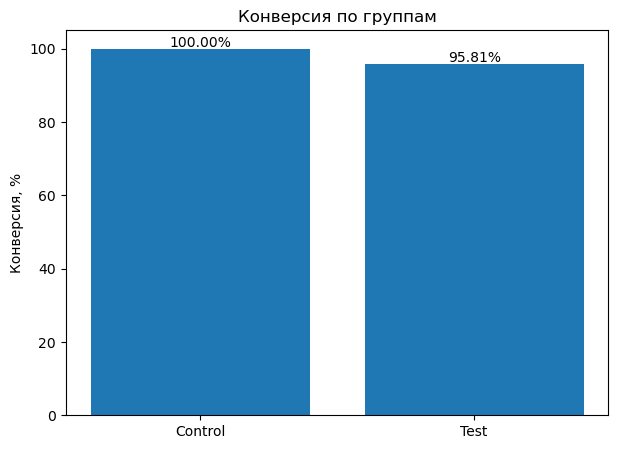

In [143]:
plt.figure(figsize=(7, 5))

conversion_values = [
    ab_summary.loc["control", "conversion"] * 100,
    ab_summary.loc["test", "conversion"] * 100
]

plt.bar(
    ["Control", "Test"],
    conversion_values
)

plt.title("Конверсия по группам")
plt.ylabel("Конверсия, %")

for i, value in enumerate(conversion_values):
    plt.text(
        i,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

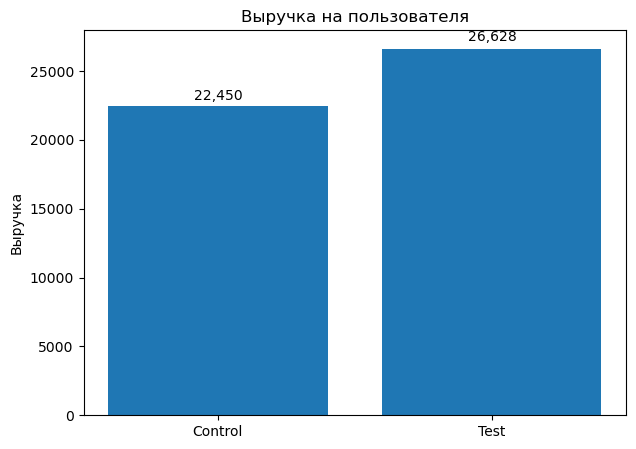

In [144]:
plt.figure(figsize=(7, 5))

revenue_values = [
    ab_summary.loc["control", "revenue_per_user"],
    ab_summary.loc["test", "revenue_per_user"]
]

plt.bar(
    ["Control", "Test"],
    revenue_values
)

plt.title("Выручка на пользователя")
plt.ylabel("Выручка")

for i, value in enumerate(revenue_values):
    plt.text(
        i,
        value + value * 0.02,
        f"{value:,.0f}",
        ha="center"
    )

plt.show()

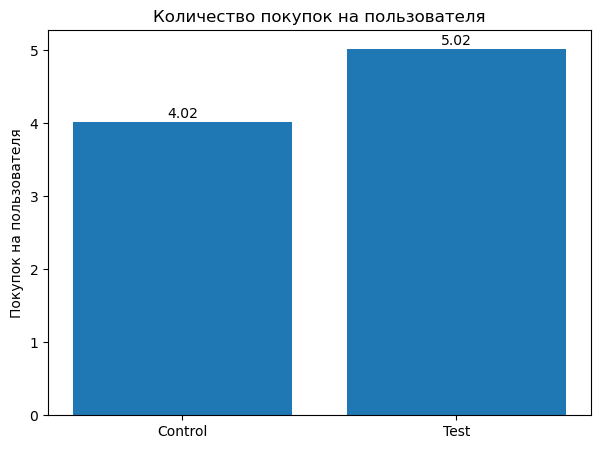

In [145]:
plt.figure(figsize=(7, 5))

purchase_values = [
    ab_summary.loc["control", "purchases_per_user"],
    ab_summary.loc["test", "purchases_per_user"]
]

plt.bar(
    ["Control", "Test"],
    purchase_values
)

plt.title("Количество покупок на пользователя")
plt.ylabel("Покупок на пользователя")

for i, value in enumerate(purchase_values):
    plt.text(
        i,
        value + 0.05,
        f"{value:.2f}",
        ha="center"
    )

plt.show()

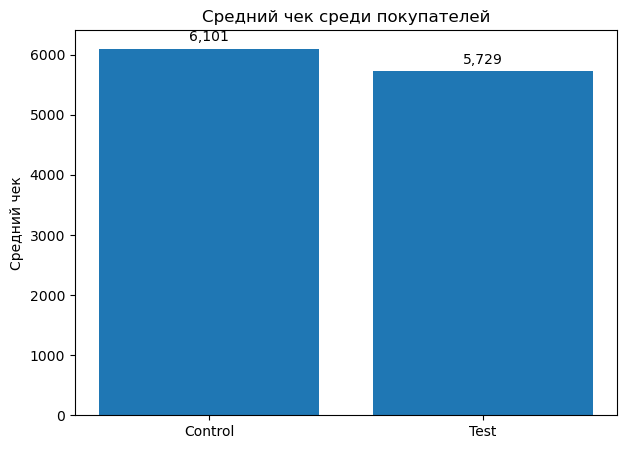

In [146]:
plt.figure(figsize=(7, 5))

check_values = [
    ab_summary.loc["control", "avg_check_buyers"],
    ab_summary.loc["test", "avg_check_buyers"]
]

plt.bar(
    ["Control", "Test"],
    check_values
)

plt.title("Средний чек среди покупателей")
plt.ylabel("Средний чек")

for i, value in enumerate(check_values):
    plt.text(
        i,
        value + value * 0.02,
        f"{value:,.0f}",
        ha="center"
    )

plt.show()

In [147]:
discount_by_group = (
    ab_purchases
    .groupby("group")["base_sale"]
    .agg(
        purchases="size",
        discounted_purchases="sum",
        discount_share="mean"
    )
)

display(discount_by_group)

,purchases,discounted_purchases,discount_share
group,,,
control,19915,6000,0.301280
test,25015,7540,0.301419


In [148]:
discount_by_day = (
    ab_purchases
    .groupby(
        ["dt", "group"]
    )["base_sale"]
    .mean()
    .reset_index()
)

display(discount_by_day)

,dt,group,base_sale
0,5,control,0.248739
1,5,test,0.264881
2,6,control,0.248217
3,6,test,0.285090
4,7,control,0.273273
5,7,test,0.303030
6,8,control,0.247817
7,8,test,0.300000
8,9,control,0.271097
9,9,test,0.310329


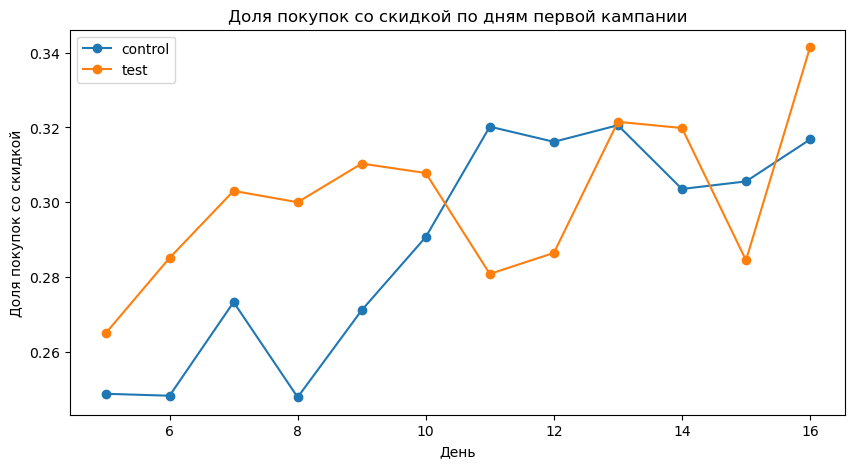

In [149]:
plt.figure(figsize=(10, 5))

for group_name in ["control", "test"]:
    subset = discount_by_day[
        discount_by_day["group"] == group_name
    ]

    plt.plot(
        subset["dt"],
        subset["base_sale"],
        marker="o",
        label=group_name
    )

plt.title(
    "Доля покупок со скидкой по дням первой кампании"
)
plt.xlabel("День")
plt.ylabel("Доля покупок со скидкой")
plt.legend()

plt.show()

## Итог первой маркетинговой кампании

Персональная кампания оказала заметное влияние на покупательское поведение.

В тестовой группе:

- выручка на пользователя выросла примерно на 18.6%;
- число покупок на пользователя выросло примерно на 25%;
- средний чек снизился примерно на 6.1%;
- конверсия снизилась примерно на 4.19 п.п.

Все рассмотренные различия статистически значимы.

Основной положительный эффект кампании связан не с ростом среднего чека,
а с увеличением частоты покупок.

С точки зрения выручки кампания выглядит эффективной, однако перед
масштабированием следует учитывать влияние предоставляемой скидки на маржинальность.

In [150]:
cluster_features = [
    "age",
    "personal_coef",
    "purchase_count",
    "total_spend",
    "avg_check",
    "unique_products",
    "active_days",
    "discount_share",
    "recency",
    "female_product_share",
    "male_product_share",
    "unisex_product_share",
    "multicolour_share"
]

X_cluster = client_mart[
    cluster_features
].copy()

In [151]:
display(
    X_cluster.describe().T
)

,count,mean,std,min,25%,50%,75%,max
age,104437.0,38.026437,12.287700,5.0000,30.000000,38.000000,46.000000,7.700000e+01
personal_coef,104437.0,0.459032,0.062008,0.2576,0.430400,0.468800,0.507200,5.584000e-01
purchase_count,104437.0,7.469699,9.620226,1.0000,3.000000,5.000000,9.000000,5.690000e+02
total_spend,104437.0,40429.793847,75131.883584,50.0000,10998.000000,22295.000000,44844.000000,5.765079e+06
avg_check,104437.0,5882.973586,6975.514022,50.0000,2591.187500,4059.000000,6609.250000,3.599990e+05
unique_products,104437.0,6.418041,7.263261,1.0000,3.000000,5.000000,8.000000,4.480000e+02
active_days,104437.0,4.586258,3.563654,1.0000,3.000000,4.000000,5.000000,5.800000e+01
discount_share,104437.0,0.327894,0.274275,0.0000,0.000000,0.333333,0.500000,1.000000e+00
recency,104437.0,17.204592,14.401018,0.0000,5.000000,14.000000,28.000000,5.800000e+01
female_product_share,104437.0,0.235841,0.326254,0.0000,0.000000,0.000000,0.444444,1.000000e+00


In [152]:
skewness = (
    X_cluster
    .skew()
    .sort_values(
        ascending=False
    )
)

display(skewness)

total_spend             21.429039
unique_products         11.769141
purchase_count          11.535797
avg_check                7.550196
active_days              3.721616
multicolour_share        1.430890
female_product_share     1.161026
recency                  0.717523
discount_share           0.557463
male_product_share       0.533570
unisex_product_share     0.388375
age                      0.160900
personal_coef           -1.356581
dtype: float64

In [153]:
X_cluster_prepared = X_cluster.copy()

In [154]:
log_features = [
    "purchase_count",
    "total_spend",
    "avg_check",
    "unique_products",
    "active_days"
]

for col in log_features:
    X_cluster_prepared[col] = np.log1p(
        X_cluster_prepared[col]
    )

In [155]:
from sklearn.preprocessing import StandardScaler

scaler_cluster = StandardScaler()

X_cluster_scaled = scaler_cluster.fit_transform(
    X_cluster_prepared
)

In [156]:
X_cluster_scaled.shape

(104437, 13)

In [157]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [158]:
cluster_results = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        X_cluster_scaled
    )

    silhouette = silhouette_score(
        X_cluster_scaled,
        labels,
        sample_size=10000,
        random_state=42
    )

    cluster_results.append({
        "k": k,
        "inertia": kmeans.inertia_,
        "silhouette": silhouette
    })

cluster_results = pd.DataFrame(
    cluster_results
)

display(cluster_results)

,k,inertia,silhouette
0,2,1.122700e+06,0.146018
1,3,1.010842e+06,0.136745
2,4,9.127004e+05,0.152406
3,5,8.548187e+05,0.148508
4,6,8.010365e+05,0.154611
5,7,7.632887e+05,0.141673
6,8,7.311369e+05,0.141356


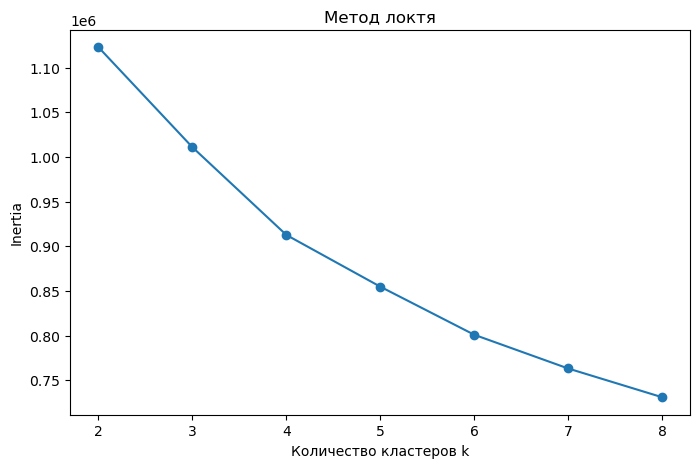

In [159]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_results["k"],
    cluster_results["inertia"],
    marker="o"
)

plt.title("Метод локтя")
plt.xlabel("Количество кластеров k")
plt.ylabel("Inertia")

plt.show()

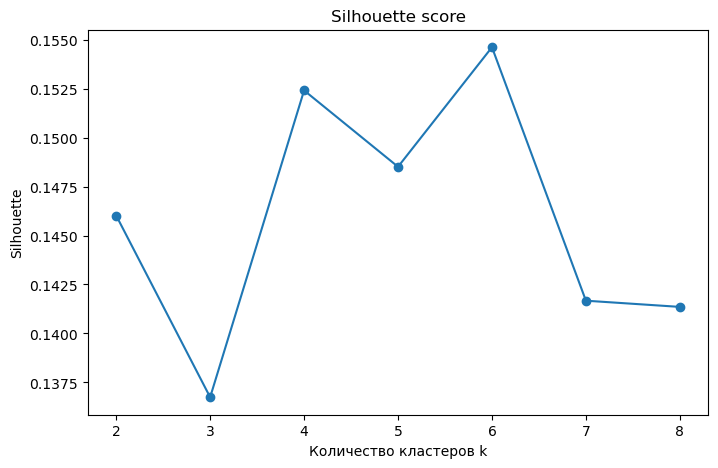

In [160]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_results["k"],
    cluster_results["silhouette"],
    marker="o"
)

plt.title("Silhouette score")
plt.xlabel("Количество кластеров k")
plt.ylabel("Silhouette")

plt.show()

## Подготовка данных к кластеризации

Для сегментации клиентов были выбраны числовые признаки,
характеризующие демографию и покупательское поведение:

- возраст;
- персональный коэффициент;
- количество покупок;
- общая сумма покупок;
- средний чек;
- количество уникальных товаров;
- количество активных дней;
- доля покупок со скидкой;
- recency;
- предпочтения по гендерной категории товара;
- доля мультицветных товаров.

Технические идентификаторы и категориальные признаки высокой
размерности на первом этапе не использовались.

Для сильно скошенных денежных и частотных признаков применено
логарифмическое преобразование `log1p`.

После этого все признаки были стандартизированы с помощью
`StandardScaler`.

Оптимальное количество кластеров оценивается совместно
по методу локтя, silhouette score и бизнес-интерпретируемости
полученных сегментов.

In [161]:
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_6 = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

labels_4 = kmeans_4.fit_predict(
    X_cluster_scaled
)

labels_6 = kmeans_6.fit_predict(
    X_cluster_scaled
)

In [162]:
clusters_4 = client_mart.copy()
clusters_4["cluster"] = labels_4

clusters_6 = client_mart.copy()
clusters_6["cluster"] = labels_6

In [163]:
print("k = 4")

display(
    clusters_4["cluster"]
    .value_counts()
    .sort_index()
)

print("\nk = 6")

display(
    clusters_6["cluster"]
    .value_counts()
    .sort_index()
)

k = 4


cluster
0    21310
1    29711
2    26355
3    27061
Name: count, dtype: int64


k = 6


cluster
0    24269
1    19177
2    21099
3    18237
4     6096
5    15559
Name: count, dtype: int64

In [164]:
cluster_sizes_4 = (
    clusters_4["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

cluster_sizes_6 = (
    clusters_6["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Доли кластеров, k=4:")
display(cluster_sizes_4)

print("Доли кластеров, k=6:")
display(cluster_sizes_6)

Доли кластеров, k=4:


cluster
0    20.40
1    28.45
2    25.24
3    25.91
Name: proportion, dtype: float64

Доли кластеров, k=6:


cluster
0    23.24
1    18.36
2    20.20
3    17.46
4     5.84
5    14.90
Name: proportion, dtype: float64

In [165]:
profile_features = [
    "age",
    "purchase_count",
    "total_spend",
    "avg_check",
    "unique_products",
    "active_days",
    "discount_share",
    "recency",
    "female_product_share",
    "male_product_share",
    "unisex_product_share",
    "multicolour_share"
]

In [166]:
profile_4 = (
    clusters_4
    .groupby("cluster")[profile_features]
    .mean()
    .round(2)
)

display(profile_4)

,age,purchase_count,total_spend,avg_check,unique_products,active_days,discount_share,recency,female_product_share,male_product_share,unisex_product_share,multicolour_share
cluster,,,,,,,,,,,,
0,40.93,5.34,20228.74,4099.59,4.80,3.59,0.44,18.55,0.75,0.08,0.18,0.15
1,36.74,4.12,26993.44,6974.80,3.78,3.20,0.33,19.84,0.05,0.78,0.17,0.25
2,38.53,16.63,93510.60,6334.40,13.58,8.58,0.35,9.29,0.20,0.36,0.44,0.18
3,36.66,3.90,19393.88,5648.96,3.62,3.00,0.22,20.97,0.07,0.12,0.81,0.18


In [167]:
profile_6 = (
    clusters_6
    .groupby("cluster")[profile_features]
    .mean()
    .round(2)
)

display(profile_6)

,age,purchase_count,total_spend,avg_check,unique_products,active_days,discount_share,recency,female_product_share,male_product_share,unisex_product_share,multicolour_share
cluster,,,,,,,,,,,,
0,39.24,4.14,21807.93,5543.27,3.77,3.19,0.34,20.05,0.05,0.82,0.13,0.22
1,41.71,5.45,20240.84,3989.71,4.89,3.64,0.44,18.48,0.76,0.07,0.16,0.15
2,39.84,18.62,93598.75,5004.18,15.03,9.32,0.37,8.55,0.22,0.38,0.40,0.17
3,38.53,3.80,8818.33,2507.74,3.52,2.90,0.26,21.27,0.08,0.12,0.79,0.14
4,15.40,5.58,30924.57,5955.43,5.02,3.85,0.33,19.01,0.21,0.37,0.42,0.25
5,37.40,5.08,63035.86,13865.85,4.71,3.78,0.18,17.47,0.09,0.23,0.68,0.27


In [168]:
gender_profile_4 = (
    clusters_4
    .groupby("cluster")["gender"]
    .mean()
    .round(3)
)

gender_profile_6 = (
    clusters_6
    .groupby("cluster")["gender"]
    .mean()
    .round(3)
)

print("Gender share, k=4:")
display(gender_profile_4)

print("Gender share, k=6:")
display(gender_profile_6)

Gender share, k=4:


cluster
0    0.128
1    0.863
2    0.606
3    0.573
Name: gender, dtype: float64

Gender share, k=6:


cluster
0    0.853
1    0.121
2    0.575
3    0.488
4    0.690
5    0.744
Name: gender, dtype: float64

In [169]:
discount_profile_4 = (
    clusters_4
    .groupby("cluster")
    .agg(
        clients=("id", "nunique"),
        avg_discount_share=(
            "discount_share",
            "mean"
        ),
        avg_purchase_count=(
            "purchase_count",
            "mean"
        ),
        avg_total_spend=(
            "total_spend",
            "mean"
        )
    )
    .round(3)
)

display(discount_profile_4)

,clients,avg_discount_share,avg_purchase_count,avg_total_spend
cluster,,,,
0,21310,0.441,5.344,20228.744
1,29711,0.329,4.119,26993.437
2,26355,0.346,16.634,93510.603
3,27061,0.219,3.898,19393.885


In [170]:
discount_profile_6 = (
    clusters_6
    .groupby("cluster")
    .agg(
        clients=("id", "nunique"),
        avg_discount_share=(
            "discount_share",
            "mean"
        ),
        avg_purchase_count=(
            "purchase_count",
            "mean"
        ),
        avg_total_spend=(
            "total_spend",
            "mean"
        )
    )
    .round(3)
)

display(discount_profile_6)

,clients,avg_discount_share,avg_purchase_count,avg_total_spend
cluster,,,,
0,24269,0.344,4.136,21807.929
1,19177,0.441,5.452,20240.838
2,21099,0.372,18.620,93598.754
3,18237,0.263,3.802,8818.331
4,6096,0.329,5.576,30924.574
5,15559,0.179,5.078,63035.863


### Предварительный выбор количества кластеров

Наибольшее значение silhouette score получено при `k = 6`
(около `0.155`).

При `k = 4` значение silhouette составляет около `0.152`,
то есть различие между вариантами невелико.

Метод локтя также указывает на область примерно от 4 до 6 кластеров.

Поскольку математические метрики не дают однозначного преимущества
одному варианту, окончательное количество кластеров будет выбрано
после сравнения размеров и бизнес-профилей сегментов.

Невысокие абсолютные значения silhouette показывают, что клиентская
база не разделяется на полностью изолированные естественные группы,
поэтому при выборе количества кластеров особенно важна
интерпретируемость сегментов.

### Выбор итогового количества кластеров

Для итоговой сегментации выбрано `k = 6`.

Данный вариант показал максимальный silhouette score среди рассмотренных
значений (`≈ 0.155`) и при этом сформировал содержательные
и достаточно крупные клиентские сегменты.

По сравнению с `k = 4`, разбиение на 6 кластеров дополнительно позволяет
выделить:

- отдельный молодой сегмент клиентов;
- высокочековый сегмент с относительно низкой долей покупок со скидкой.

Минимальный кластер составляет около 5.8% клиентской базы,
поэтому полученные дополнительные сегменты не являются небольшими
группами единичных аномальных наблюдений.

Таким образом, `k = 6` обеспечивает более детальную и полезную
для бизнеса сегментацию при сопоставимом качестве кластеризации.

In [171]:
client_mart_clustered = client_mart.copy()

client_mart_clustered["cluster"] = labels_6

In [172]:
display(
    client_mart_clustered["cluster"]
    .value_counts()
    .sort_index()
)

cluster
0    24269
1    19177
2    21099
3    18237
4     6096
5    15559
Name: count, dtype: int64

In [173]:
cluster_names = {
    0: "Мужская категория - умеренная активность",
    1: "Женская категория - скидочно-чувствительные",
    2: "Высокоактивные постоянные клиенты",
    3: "Низкоактивные - преимущественно унисекс",
    4: "Молодая аудитория",
    5: "Высокочековые клиенты"
}

client_mart_clustered["cluster_name"] = (
    client_mart_clustered["cluster"]
    .map(cluster_names)
)

In [174]:
display(
    client_mart_clustered[
        [
            "cluster",
            "cluster_name"
        ]
    ]
    .value_counts()
    .sort_index()
)

cluster  cluster_name                               
0        Мужская категория - умеренная активность       24269
1        Женская категория - скидочно-чувствительные    19177
2        Высокоактивные постоянные клиенты              21099
3        Низкоактивные - преимущественно унисекс        18237
4        Молодая аудитория                               6096
5        Высокочековые клиенты                          15559
Name: count, dtype: int64

In [175]:
final_cluster_profile = (
    client_mart_clustered
    .groupby(
        ["cluster", "cluster_name"]
    )
    .agg(
        clients=("id", "nunique"),
        avg_age=("age", "mean"),
        avg_purchase_count=("purchase_count", "mean"),
        avg_total_spend=("total_spend", "mean"),
        avg_check=("avg_check", "mean"),
        avg_unique_products=("unique_products", "mean"),
        avg_active_days=("active_days", "mean"),
        avg_discount_share=("discount_share", "mean"),
        avg_recency=("recency", "mean"),
        female_product_share=("female_product_share", "mean"),
        male_product_share=("male_product_share", "mean"),
        unisex_product_share=("unisex_product_share", "mean")
    )
    .round(2)
)

display(final_cluster_profile)

,,clients,avg_age,avg_purchase_count,avg_total_spend,avg_check,avg_unique_products,avg_active_days,avg_discount_share,avg_recency,female_product_share,male_product_share,unisex_product_share
cluster,cluster_name,,,,,,,,,,,,
0,Мужская категория - умеренная активность,24269,39.24,4.14,21807.93,5543.27,3.77,3.19,0.34,20.05,0.05,0.82,0.13
1,Женская категория - скидочно-чувствительные,19177,41.71,5.45,20240.84,3989.71,4.89,3.64,0.44,18.48,0.76,0.07,0.16
2,Высокоактивные постоянные клиенты,21099,39.84,18.62,93598.75,5004.18,15.03,9.32,0.37,8.55,0.22,0.38,0.40
3,Низкоактивные - преимущественно унисекс,18237,38.53,3.80,8818.33,2507.74,3.52,2.90,0.26,21.27,0.08,0.12,0.79
4,Молодая аудитория,6096,15.40,5.58,30924.57,5955.43,5.02,3.85,0.33,19.01,0.21,0.37,0.42
5,Высокочековые клиенты,15559,37.40,5.08,63035.86,13865.85,4.71,3.78,0.18,17.47,0.09,0.23,0.68


In [176]:
purchase_clusters = (
    purchases_clean
    .merge(
        client_mart_clustered[
            [
                "id",
                "cluster",
                "cluster_name"
            ]
        ],
        on="id",
        how="inner"
    )
)

print(
    "Размер purchase_clusters:",
    purchase_clusters.shape
)

print(
    "Уникальных клиентов:",
    purchase_clusters["id"].nunique()
)

Размер purchase_clusters: (780113, 18)
Уникальных клиентов: 104437


In [177]:
top_products = (
    purchase_clusters
    .groupby(
        [
            "cluster",
            "cluster_name",
            "product_clean"
        ]
    )
    .size()
    .reset_index(
        name="purchase_count"
    )
)

top_products["rank"] = (
    top_products
    .groupby("cluster")[
        "purchase_count"
    ]
    .rank(
        method="first",
        ascending=False
    )
)

top_products_5 = (
    top_products[
        top_products["rank"] <= 5
    ]
    .sort_values(
        ["cluster", "rank"]
    )
)

display(top_products_5)

,cluster,cluster_name,product_clean,purchase_count,rank
759,0,Мужская категория - умеренная активность,брюки мужские demix,1431,1.0
9240,0,Мужская категория - умеренная активность,шорты мужские demix,1387,2.0
859,0,Мужская категория - умеренная активность,брюки мужские outventure,1029,3.0
8398,0,Мужская категория - умеренная активность,футболка мужская demix,1015,4.0
768,0,Мужская категория - умеренная активность,брюки мужские fila,804,5.0
13837,1,Женская категория - скидочно-чувствительные,лиф женский joss,1484,1.0
14801,1,Женская категория - скидочно-чувствительные,плавки женские joss,1254,2.0
17082,1,Женская категория - скидочно-чувствительные,футболка женская demix,1233,3.0
13305,1,Женская категория - скидочно-чувствительные,купальник женский joss,1184,4.0
10189,1,Женская категория - скидочно-чувствительные,брюки женские outventure,996,5.0


In [178]:
top_colours = (
    purchase_clusters
    .groupby(
        [
            "cluster",
            "cluster_name",
            "main_colour"
        ]
    )
    .size()
    .reset_index(
        name="purchase_count"
    )
)

top_colours["rank"] = (
    top_colours
    .groupby("cluster")[
        "purchase_count"
    ]
    .rank(
        method="first",
        ascending=False
    )
)

top_colours_5 = (
    top_colours[
        top_colours["rank"] <= 5
    ]
    .sort_values(
        ["cluster", "rank"]
    )
)

display(top_colours_5)

,cluster,cluster_name,main_colour,purchase_count,rank
185,0,Мужская категория - умеренная активность,черный,31198,1.0
1,0,Мужская категория - умеренная активность,unknown,19293,2.0
8,0,Мужская категория - умеренная активность,белый,8360,3.0
150,0,Мужская категория - умеренная активность,синий,6366,4.0
147,0,Мужская категория - умеренная активность,серый,6086,5.0
374,1,Женская категория - скидочно-чувствительные,черный,21030,1.0
205,1,Женская категория - скидочно-чувствительные,unknown,17827,2.0
213,1,Женская категория - скидочно-чувствительные,белый,11074,3.0
211,1,Женская категория - скидочно-чувствительные,бежевый,5580,4.0
345,1,Женская категория - скидочно-чувствительные,синий,5556,5.0


In [179]:
product_sex_by_cluster = (
    purchase_clusters
    .groupby(
        [
            "cluster",
            "product_sex_clean"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

product_sex_share = (
    product_sex_by_cluster
    .div(
        product_sex_by_cluster.sum(
            axis=1
        ),
        axis=0
    )
    .round(3)
)

display(product_sex_share)

product_sex_clean,-1,0,1
cluster,,,
0,0.138,0.047,0.815
1,0.181,0.749,0.070
2,0.400,0.242,0.358
3,0.790,0.085,0.125
4,0.417,0.223,0.360
5,0.681,0.084,0.235


In [180]:
discount_behavior = (
    purchase_clusters
    .groupby("cluster")
    .agg(
        purchases=(
            "product_clean",
            "size"
        ),
        clients=(
            "id",
            "nunique"
        ),
        discount_share=(
            "base_sale",
            "mean"
        ),
        avg_check=(
            "cost",
            "mean"
        )
    )
    .round(3)
)

display(discount_behavior)

,purchases,clients,discount_share,avg_check
cluster,,,,
0,100370,24269,0.356,5273.056
1,104555,19177,0.458,3712.482
2,392860,21099,0.379,5026.829
3,69330,18237,0.276,2319.629
4,33993,6096,0.345,5545.736
5,79005,15559,0.183,12414.088


In [181]:
check_by_discount = (
    purchase_clusters
    .groupby(
        [
            "cluster",
            "base_sale"
        ]
    )
    .agg(
        purchases=(
            "product_clean",
            "size"
        ),
        avg_check=(
            "cost",
            "mean"
        ),
        median_check=(
            "cost",
            "median"
        )
    )
    .reset_index()
)

display(check_by_discount)

,cluster,base_sale,purchases,avg_check,median_check
0,0,0,64642,5818.529099,4199.0
1,0,1,35728,4286.141822,3499.0
2,1,0,56622,4253.810074,3024.0
3,1,1,47933,3073.024993,2499.0
4,2,0,243901,5874.974740,2999.0
5,2,1,148959,3638.101082,2699.0
6,3,0,50205,2355.700090,1699.0
7,3,1,19125,2224.940026,1799.0
8,4,0,22256,6368.155643,3399.0
9,4,1,11737,3986.242651,2849.0


In [182]:
client_discount = (
    purchase_clusters
    .groupby(
        ["cluster", "id"]
    )["base_sale"]
    .max()
    .reset_index(
        name="used_discount"
    )
)

discount_client_share = (
    client_discount
    .groupby("cluster")
    .agg(
        clients=(
            "id",
            "nunique"
        ),
        clients_used_discount=(
            "used_discount",
            "sum"
        ),
        share_used_discount=(
            "used_discount",
            "mean"
        )
    )
    .round(3)
)

display(discount_client_share)

,clients,clients_used_discount,share_used_discount
cluster,,,
0,24269,17334,0.714
1,19177,16262,0.848
2,21099,20467,0.970
3,18237,10674,0.585
4,6096,4422,0.725
5,15559,8832,0.568


In [183]:
discount_cluster_summary = (
    purchase_clusters
    .groupby(
        [
            "cluster",
            "base_sale"
        ]
    )
    .agg(
        purchases=(
            "product_clean",
            "size"
        ),
        unique_clients=(
            "id",
            "nunique"
        ),
        revenue=(
            "cost",
            "sum"
        ),
        avg_check=(
            "cost",
            "mean"
        )
    )
    .reset_index()
)

display(discount_cluster_summary)

,cluster,base_sale,purchases,unique_clients,revenue,avg_check
0,0,0,64642,22727,376121358,5818.529099
1,0,1,35728,17334,153135275,4286.141822
2,1,0,56622,17776,240859234,4253.810074
3,1,1,47933,16262,147299307,3073.024993
4,2,0,243901,21065,1432912214,5874.974740
5,2,1,148959,20467,541927899,3638.101082
6,3,0,50205,17374,118267923,2355.700090
7,3,1,19125,10674,42551978,2224.940026
8,4,0,22256,5792,141729672,6368.155643
9,4,1,11737,4422,46786530,3986.242651


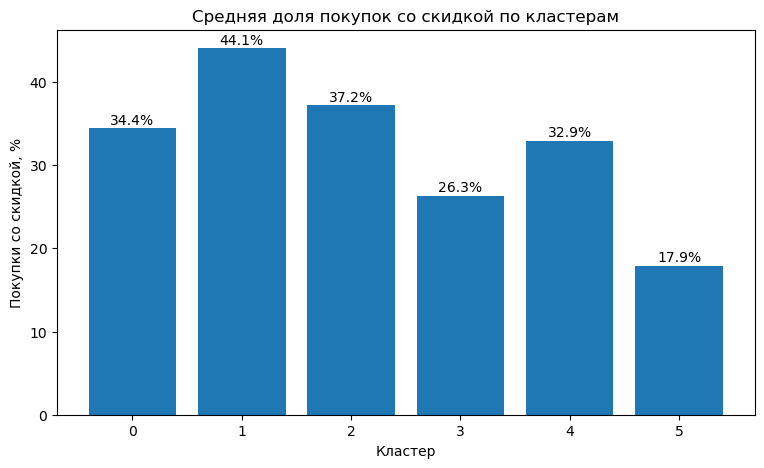

In [184]:
discount_plot = (
    client_mart_clustered
    .groupby("cluster")[
        "discount_share"
    ]
    .mean()
    .sort_index()
)

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    discount_plot.index.astype(str),
    discount_plot.values * 100
)

plt.title(
    "Средняя доля покупок со скидкой по кластерам"
)

plt.xlabel("Кластер")
plt.ylabel("Покупки со скидкой, %")

for i, value in enumerate(
    discount_plot.values * 100
):
    plt.text(
        i,
        value + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.show()

## Интерпретация клиентских сегментов

После выбора `k = 6` были изучены покупательские характеристики
каждого сегмента, товарные предпочтения и использование скидок.

Кластеры различаются не только по общей активности и среднему чеку,
но также по:

- предпочитаемой гендерной категории товаров;
- частоте покупок;
- recency;
- общей сумме расходов;
- использованию скидок;
- товарным и цветовым предпочтениям.

Особенно выделяются:

- высокоактивные постоянные клиенты;
- высокочековый сегмент с относительно низкой долей скидочных покупок;
- скидочно-чувствительный сегмент с выраженным предпочтением женских товаров;
- молодая аудитория;
- низкоактивный сегмент с преобладанием товаров без указанной
  гендерной категории.

Полученные сегменты могут использоваться для настройки различных
маркетинговых стратегий и персональных предложений.

## Бизнес-рекомендации по клиентским сегментам

### Кластер 0 - Мужская категория, умеренная активность

Сегмент характеризуется выраженным предпочтением мужских товаров
и средней покупательской активностью.

Рекомендации:

- продвигать мужские категории одежды, обуви и спортивных товаров;
- использовать персональные подборки на основе прошлых покупок;
- применять умеренные скидки и кросс-сейл сопутствующих товаров;
- стимулировать повторные покупки через рекомендации похожих товаров.

---

### Кластер 1 - Женская категория, скидочно-чувствительные

Клиенты сегмента чаще других покупают женские товары и имеют
самую высокую долю покупок со скидкой.

Рекомендации:

- активно использовать персональные скидки и промокоды;
- запускать акции на женские категории;
- использовать ограниченные по времени предложения;
- тестировать механики bundle-offer и скидки на повторную покупку;
- контролировать маржинальность, так как высокая доля скидочных покупок
  может снижать прибыль.

---

### Кластер 2 - Высокоактивные постоянные клиенты

Это один из самых ценных сегментов:
клиенты совершают больше всего покупок, имеют высокие суммарные расходы
и небольшое значение recency.

Рекомендации:

- развивать программы лояльности;
- предоставлять ранний доступ к новым коллекциям и товарам;
- использовать персональные рекомендации;
- предлагать cross-sell и up-sell;
- избегать чрезмерных скидок для клиентов, которые готовы покупать
  и без дополнительного стимулирования;
- использовать сегмент для retention-кампаний и VIP-механик.

---

### Кластер 3 - Низкоактивные, преимущественно унисекс

Сегмент отличается невысокой частотой покупок и сравнительно низкими расходами.
Большая часть покупок приходится на товары без указанной гендерной категории.

Рекомендации:

- использовать реактивационные кампании;
- делать акцент на универсальные товары;
- применять простые промо-механики для увеличения частоты покупок;
- тестировать персональные предложения с невысоким порогом входа;
- анализировать причины низкой активности отдельно.

---

### Кластер 4 - Молодая аудитория

Сегмент существенно моложе остальных и имеет отдельный покупательский профиль.

Рекомендации:

- продвигать товары, ориентированные на молодую аудиторию;
- использовать более доступные ценовые предложения;
- делать упор на популярные модели и спортивные категории;
- тестировать сезонные акции и наборы;
- учитывать возрастные особенности при выборе каналов коммуникации
  и маркетинговых сообщений.

---

### Кластер 5 - Высокочековые клиенты

Сегмент отличается самым высоким средним чеком и относительно низкой
долей покупок со скидкой.

Рекомендации:

- использовать премиальные предложения;
- делать акцент на дорогие категории и комплекты;
- применять персональные рекомендации вместо массовых скидок;
- развивать up-sell;
- предлагать эксклюзивные товары и дополнительные сервисы;
- не снижать цену без необходимости, так как клиенты сегмента
  демонстрируют сравнительно низкую зависимость от скидок.

## Итог кластеризации

Для сегментации клиентской базы была применена модель K-Means.

Количество кластеров выбиралось на основе сочетания:

- метода локтя;
- silhouette score;
- размеров полученных сегментов;
- бизнес-интерпретируемости профилей.

Итоговым выбрано `k = 6`.

Silhouette score составил около `0.155`.
Значение невысокое, поэтому сегменты нельзя считать полностью
изолированными естественными группами. Тем не менее кластеризация
позволила выделить несколько устойчиво интерпретируемых клиентских профилей.

В частности были выделены:

- сегмент с преимущественным интересом к мужским товарам;
- скидочно-чувствительный сегмент с интересом к женским товарам;
- высокоактивные постоянные клиенты;
- низкоактивный сегмент с преобладанием универсальных товаров;
- молодая аудитория;
- высокочековые клиенты.

Анализ товарных предпочтений и использования скидок подтвердил,
что сегменты различаются не только по финансовым и поведенческим метрикам,
но и по структуре покупок.

Полученные кластеры могут использоваться как основа для персонализации
маркетинговых коммуникаций и дальнейшего построения модели склонности к покупке.

In [185]:
client_mart_clustered.to_pickle(
    "client_mart_clustered.pkl"
)

client_mart_clustered.to_csv(
    "client_mart_clustered.csv",
    index=False
)

In [186]:
purchase_clusters.to_pickle(
    "purchase_clusters.pkl"
)

In [187]:
city_1188_clients = (
    client_mart_clustered[
        client_mart_clustered["city"] == 1188
    ]
    .copy()
)

print(
    "Клиентов города 1188:",
    city_1188_clients["id"].nunique()
)

display(
    city_1188_clients.head()
)

Клиентов города 1188: 12438


,id,gender,age,education,city,country,personal_coef,gender_source,purchase_count,total_spend,avg_check,median_check,min_check,max_check,unique_products,unique_colours,active_days,first_purchase_day,last_purchase_day,discount_share,multicolour_share,recency,female_product_share,male_product_share,unisex_product_share,favorite_colour,favorite_product_sex,cluster,cluster_name
2,6,1,52,среднее,1188,32,0.4304,original,15,84085,5605.666667,3779.0,299,23999,13,5,9,1,30,0.400000,0.333333,28,0.000000,0.600000,0.40,черный,1,2,Высокоактивные постоянные клиенты
9,18,1,53,среднее,1188,32,0.4304,original,17,155123,9124.882353,8399.0,799,22879,15,8,13,11,50,0.294118,0.235294,8,0.176471,0.823529,0.00,черный,1,2,Высокоактивные постоянные клиенты
20,39,1,21,высшее,1188,32,0.4688,original,7,36593,5227.571429,3999.0,499,19599,7,5,4,30,47,0.571429,0.142857,11,0.000000,1.000000,0.00,черный,1,0,Мужская категория - умеренная активность
21,40,1,35,высшее,1188,32,0.4688,original,5,76275,15255.000000,14999.0,2999,25999,5,3,4,5,46,0.000000,0.400000,12,0.600000,0.400000,0.00,черный,0,5,Высокочековые клиенты
44,88,0,37,среднее,1188,32,0.5072,original,4,21296,5324.000000,2749.0,799,14999,4,4,4,13,38,0.250000,0.000000,20,0.250000,0.000000,0.75,еловый,-1,3,Низкоактивные - преимущественно унисекс


In [188]:
display(
    city_1188_clients["cluster_name"]
    .value_counts()
)

cluster_name
Мужская категория - умеренная активность       2917
Женская категория - скидочно-чувствительные    2508
Высокоактивные постоянные клиенты              2386
Низкоактивные - преимущественно унисекс        2159
Высокочековые клиенты                          1853
Молодая аудитория                               615
Name: count, dtype: int64

In [189]:
city_1188_ids = set(
    city_1188_clients["id"]
)

city_1188_purchases = (
    purchases_clean[
        purchases_clean["id"].isin(
            city_1188_ids
        )
    ]
    .copy()
)

print(
    "Покупок:",
    len(city_1188_purchases)
)

print(
    "Покупателей:",
    city_1188_purchases["id"].nunique()
)

print(
    "Уникальных товаров:",
    city_1188_purchases["product_clean"].nunique()
)

Покупок: 88888
Покупателей: 12438
Уникальных товаров: 12363


In [190]:
top_city_1188_products = (
    city_1188_purchases["product_clean"]
    .value_counts()
    .head(20)
)

display(
    top_city_1188_products
)

product_clean
брюки мужские demix                  461
шорты мужские demix                  403
лиф женский joss                     394
футболка женская demix               349
брюки мужские outventure             344
футболка мужская demix               325
брюки женские outventure             321
плавки женские joss                  279
купальник женский joss               274
сабо crocs crocband                  254
брюки мужские fila                   251
легинсы женские demix                241
ветровка женская outventure          228
брюки женские demix                  217
сумка fila                           202
брюки женские fila                   201
купальник женский fila               198
балетки женские demix ballerina 2    196
лиф женский termit                   191
рюкзак demix                         188
Name: count, dtype: int64

In [191]:
HISTORY_END = 44
TARGET_START = 45
TARGET_END = 58

In [192]:
purchases_history = (
    purchases_clean[
        purchases_clean["dt"] <= HISTORY_END
    ]
    .copy()
)

purchases_future = (
    purchases_clean[
        purchases_clean["dt"]
        .between(
            TARGET_START,
            TARGET_END
        )
    ]
    .copy()
)

print(
    "История:",
    purchases_history.shape
)

print(
    "Будущий период:",
    purchases_future.shape
)

История: (636671, 16)
Будущий период: (149585, 16)


In [193]:
future_products = (
    purchases_future["product_clean"]
    .value_counts()
    .head(20)
)

display(
    future_products
)

product_clean
шорты мужские demix              813
брюки мужские demix              794
лиф женский joss                 700
купальник женский joss           675
плавки женские joss              642
футболка мужская demix           633
брюки мужские fila               614
футболка женская demix           486
ветровка женская outventure      462
сабо crocs crocband              460
сумка demix                      414
брюки мужские outventure         397
брюки женские outventure         393
легинсы женские demix            390
купальник женский fila           385
футболка мужская termit          373
кресло кемпинговое outventure    365
футболка мужская fila            359
футболка женская protest         347
рюкзак demix                     335
Name: count, dtype: int64

In [194]:
future_city_1188 = (
    purchases_future[
        purchases_future["id"].isin(
            city_1188_ids
        )
    ]
)

display(
    future_city_1188["product_clean"]
    .value_counts()
    .head(20)
)

product_clean
лиф женский joss                        80
купальник женский joss                  71
брюки мужские demix                     63
шорты мужские demix                     61
плавки женские joss                     59
сабо crocs crocband                     59
ветровка женская outventure             58
футболка мужская demix                  56
брюки женские outventure                55
футболка женская demix                  53
брюки мужские fila                      52
легинсы женские demix                   46
купальник женский fila                  42
шорты плавательные мужские joss         41
футболка женская protest                41
шорты женские termit                    37
кресло кемпинговое outventure           37
брюки мужские outventure                36
балетки женские demix ballerina 2       35
куртка утепленная женская outventure    35
Name: count, dtype: int64

## Модель склонности клиента к покупке

Целевая аудитория будущей маркетинговой кампании - жители страны 32
и города 1188.

Поскольку в условии не задан конкретный товар и готовая целевая переменная,
target формируется на основе фактического покупательского поведения.

Для предотвращения утечки данных период наблюдения разделён во времени:

- дни 0-44 используются для построения признаков;
- дни 45-58 используются для формирования целевой переменной.

Целевая переменная будет равна 1, если клиент приобрёл выбранный товар
в будущем периоде, и 0 - в противном случае.

Конкретный товар выбирается среди достаточно популярных товаров,
представленных в целевой аудитории, чтобы модель имела достаточное
количество положительных наблюдений для обучения.

In [195]:
TARGET_PRODUCT = "лиф женский joss"

print("Целевой товар:", TARGET_PRODUCT)

Целевой товар: лиф женский joss


In [196]:
target_future_buyers = set(
    purchases_future.loc[
        purchases_future["product_clean"] == TARGET_PRODUCT,
        "id"
    ]
)

In [197]:
city_1188_future_buyers = (
    target_future_buyers
    & set(city_1188_clients["id"])
)

print(
    "Покупателей целевого товара в городе 1188:",
    len(city_1188_future_buyers)
)

print(
    "Всего клиентов города 1188:",
    city_1188_clients["id"].nunique()
)

print(
    "Доля target = 1:",
    round(
        len(city_1188_future_buyers)
        / city_1188_clients["id"].nunique()
        * 100,
        3
    ),
    "%"
)

Покупателей целевого товара в городе 1188: 64
Всего клиентов города 1188: 12438
Доля target = 1: 0.515 %


In [198]:
model_df = city_1188_clients.copy()

model_df["target"] = (
    model_df["id"]
    .isin(city_1188_future_buyers)
    .astype(int)
)

print(model_df["target"].value_counts())
print()
print(model_df["target"].value_counts(normalize=True) * 100)
print()
print("Размер таблицы:", model_df.shape)

target
0    12374
1       64
Name: count, dtype: int64

target
0    99.485448
1     0.514552
Name: proportion, dtype: float64

Размер таблицы: (12438, 30)


In [199]:
print(model_df.columns.tolist())

['id', 'gender', 'age', 'education', 'city', 'country', 'personal_coef', 'gender_source', 'purchase_count', 'total_spend', 'avg_check', 'median_check', 'min_check', 'max_check', 'unique_products', 'unique_colours', 'active_days', 'first_purchase_day', 'last_purchase_day', 'discount_share', 'multicolour_share', 'recency', 'female_product_share', 'male_product_share', 'unisex_product_share', 'favorite_colour', 'favorite_product_sex', 'cluster', 'cluster_name', 'target']


In [200]:
model_df.head()

,id,gender,age,education,city,country,personal_coef,gender_source,purchase_count,total_spend,avg_check,median_check,min_check,max_check,unique_products,unique_colours,active_days,first_purchase_day,last_purchase_day,discount_share,multicolour_share,recency,female_product_share,male_product_share,unisex_product_share,favorite_colour,favorite_product_sex,cluster,cluster_name,target
2,6,1,52,среднее,1188,32,0.4304,original,15,84085,5605.666667,3779.0,299,23999,13,5,9,1,30,0.400000,0.333333,28,0.000000,0.600000,0.40,черный,1,2,Высокоактивные постоянные клиенты,0
9,18,1,53,среднее,1188,32,0.4304,original,17,155123,9124.882353,8399.0,799,22879,15,8,13,11,50,0.294118,0.235294,8,0.176471,0.823529,0.00,черный,1,2,Высокоактивные постоянные клиенты,0
20,39,1,21,высшее,1188,32,0.4688,original,7,36593,5227.571429,3999.0,499,19599,7,5,4,30,47,0.571429,0.142857,11,0.000000,1.000000,0.00,черный,1,0,Мужская категория - умеренная активность,0
21,40,1,35,высшее,1188,32,0.4688,original,5,76275,15255.000000,14999.0,2999,25999,5,3,4,5,46,0.000000,0.400000,12,0.600000,0.400000,0.00,черный,0,5,Высокочековые клиенты,0
44,88,0,37,среднее,1188,32,0.5072,original,4,21296,5324.000000,2749.0,799,14999,4,4,4,13,38,0.250000,0.000000,20,0.250000,0.000000,0.75,еловый,-1,3,Низкоактивные - преимущественно унисекс,0


In [201]:
history_purchase_agg = (
    purchases_history
    .groupby("id")
    .agg(
        purchase_count=("product_clean", "size"),
        total_spend=("cost", "sum"),
        avg_check=("cost", "mean"),
        median_check=("cost", "median"),
        min_check=("cost", "min"),
        max_check=("cost", "max"),
        unique_products=("product_clean", "nunique"),
        unique_colours=("main_colour", "nunique"),
        active_days=("dt", "nunique"),
        first_purchase_day=("dt", "min"),
        last_purchase_day=("dt", "max"),
        discount_share=("base_sale", "mean"),
        multicolour_share=("is_multicolour", "mean")
    )
    .reset_index()
)

history_purchase_agg["recency"] = (
    HISTORY_END
    - history_purchase_agg["last_purchase_day"]
)

print(history_purchase_agg.shape)

display(history_purchase_agg.head())

(103154, 15)


,id,purchase_count,total_spend,avg_check,median_check,min_check,max_check,unique_products,unique_colours,active_days,first_purchase_day,last_purchase_day,discount_share,multicolour_share,recency
0,0,3,19897,6632.333333,4799.0,1499,13599,3,3,2,7,37,0.333333,0.333333,7
1,3,4,14596,3649.000000,2899.0,1599,7199,4,3,3,13,34,0.250000,0.000000,10
2,4,7,31093,4441.857143,4399.0,999,9199,7,6,4,0,32,0.000000,0.428571,12
3,6,15,84085,5605.666667,3779.0,299,23999,13,5,9,1,30,0.400000,0.333333,14
4,7,12,50028,4169.000000,3599.0,1199,8799,12,5,7,6,42,0.416667,0.250000,2


In [202]:
history_product_sex_agg = (
    purchases_history
    .groupby("id")
    .agg(
        female_product_share=(
            "female_product",
            "mean"
        ),
        male_product_share=(
            "male_product",
            "mean"
        ),
        unisex_product_share=(
            "unisex_product",
            "mean"
        )
    )
    .reset_index()
)

display(history_product_sex_agg.head())

,id,female_product_share,male_product_share,unisex_product_share
0,0,0.333333,0.00,0.666667
1,3,0.000000,0.75,0.250000
2,4,0.000000,0.00,1.000000
3,6,0.000000,0.60,0.400000
4,7,0.416667,0.00,0.583333


In [203]:
history_favorite_colour = (
    purchases_history
    .groupby(["id", "main_colour"])
    .size()
    .reset_index(name="count")
    .sort_values(
        ["id", "count"],
        ascending=[True, False]
    )
    .drop_duplicates("id")
    [["id", "main_colour"]]
    .rename(
        columns={
            "main_colour": "favorite_colour"
        }
    )
)

display(history_favorite_colour.head())

,id,favorite_colour
0,0,бежевый
3,3,белый
7,4,белый
16,6,черный
19,7,красный


In [204]:
history_favorite_product_sex = (
    purchases_history
    .groupby(
        ["id", "product_sex_clean"]
    )
    .size()
    .reset_index(name="count")
    .sort_values(
        ["id", "count"],
        ascending=[True, False]
    )
    .drop_duplicates("id")
    [["id", "product_sex_clean"]]
    .rename(
        columns={
            "product_sex_clean":
            "favorite_product_sex"
        }
    )
)

display(history_favorite_product_sex.head())

,id,favorite_product_sex
0,0,-1
3,3,1
4,4,-1
6,6,1
7,7,-1


In [205]:
model_history = (
    city_1188_clients[
        [
            "id",
            "gender",
            "age",
            "education",
            "personal_coef"
        ]
    ]
    .merge(
        history_purchase_agg,
        on="id",
        how="left"
    )
    .merge(
        history_product_sex_agg,
        on="id",
        how="left"
    )
    .merge(
        history_favorite_colour,
        on="id",
        how="left"
    )
    .merge(
        history_favorite_product_sex,
        on="id",
        how="left"
    )
)

print("Размер витртны:", model_history.shape)
display(model_history.head())

Размер витртны: (12438, 24)


,id,gender,age,education,personal_coef,purchase_count,total_spend,avg_check,median_check,min_check,max_check,unique_products,unique_colours,active_days,first_purchase_day,last_purchase_day,discount_share,multicolour_share,recency,female_product_share,male_product_share,unisex_product_share,favorite_colour,favorite_product_sex
0,6,1,52,среднее,0.4304,15.0,84085.0,5605.666667,3779.0,299.0,23999.0,13.0,5.0,9.0,1.0,30.0,0.400000,0.333333,14.0,0.000000,0.600000,0.40,черный,1.0
1,18,1,53,среднее,0.4304,15.0,124325.0,8288.333333,8399.0,799.0,22879.0,13.0,8.0,12.0,11.0,37.0,0.333333,0.266667,7.0,0.133333,0.866667,0.00,черный,1.0
2,39,1,21,высшее,0.4688,3.0,20697.0,6899.000000,599.0,499.0,19599.0,3.0,2.0,2.0,30.0,43.0,0.333333,0.333333,1.0,0.000000,1.000000,0.00,черный,1.0
3,40,1,35,высшее,0.4688,4.0,61996.0,15499.000000,16499.0,2999.0,25999.0,4.0,2.0,3.0,5.0,41.0,0.000000,0.500000,3.0,0.500000,0.500000,0.00,черный,0.0
4,88,0,37,среднее,0.5072,4.0,21296.0,5324.000000,2749.0,799.0,14999.0,4.0,4.0,4.0,13.0,38.0,0.250000,0.000000,6.0,0.250000,0.000000,0.75,еловый,-1.0


In [206]:
model_history.isna().sum().sort_values(ascending=False)

total_spend             240
avg_check               240
purchase_count          240
unique_colours          240
unique_products         240
max_check               240
min_check               240
median_check            240
discount_share          240
multicolour_share       240
recency                 240
female_product_share    240
male_product_share      240
active_days             240
first_purchase_day      240
last_purchase_day       240
favorite_colour         240
unisex_product_share    240
favorite_product_sex    240
personal_coef             0
id                        0
gender                    0
age                       0
education                 0
dtype: int64

In [207]:
model_history["target"] = (
    model_history["id"]
    .isin(city_1188_future_buyers)
    .astype(int)
)

print(model_history["target"].value_counts())
print()
print(
    model_history["target"]
    .value_counts(normalize=True)
    .mul(100)
)

target
0    12374
1       64
Name: count, dtype: int64

target
0    99.485448
1     0.514552
Name: proportion, dtype: float64


In [208]:
no_history_mask = model_history["purchase_count"].isna()

print("Клиентов без истории:", no_history_mask.sum())

print(
    "Из них target = 1:",
    model_history.loc[
        no_history_mask,
        "target"
    ].sum()
)

print(
    "Для target = 1 среди клиентов без истории:",
    round(
        model_history.loc[
            no_history_mask,
            "target"
        ].mean() * 100,
        3
    ),
    "%"
)

Клиентов без истории: 240
Из них target = 1: 1
Для target = 1 среди клиентов без истории: 0.417 %


In [209]:
zero_fill_cols = [
    "purchase_count",
    "total_spend",
    "avg_check",
    "median_check",
    "min_check",
    "max_check",
    "unique_products",
    "unique_colours",
    "active_days",
    "discount_share",
    "multicolour_share",
    "female_product_share",
    "male_product_share",
    "unisex_product_share",
]

model_history[zero_fill_cols] = (
    model_history[zero_fill_cols]
    .fillna(0)
)

In [210]:
model_history[
    [
        "first_purchase_day",
        "last_purchase_day"
    ]
] = (
    model_history[
        [
        "first_purchase_day",
        "last_purchase_day"
        ]
    ]
    .fillna(-1)
    
)

In [211]:
model_history["recency"] = (
    model_history["recency"]
    .fillna(HISTORY_END + 1)
)

In [212]:
model_history["favorite_colour"] = (
    model_history["favorite_colour"]
    .fillna("no_history")
)

model_history["favorite_product_sex"] = (
    model_history["favorite_product_sex"]
    .fillna(-2)
)

In [213]:
print(
    model_history
    .isna()
    .sum()
    .sort_values(ascending=False)
)

id                      0
gender                  0
age                     0
education               0
personal_coef           0
purchase_count          0
total_spend             0
avg_check               0
median_check            0
min_check               0
max_check               0
unique_products         0
unique_colours          0
active_days             0
first_purchase_day      0
last_purchase_day       0
discount_share          0
multicolour_share       0
recency                 0
female_product_share    0
male_product_share      0
unisex_product_share    0
favorite_colour         0
favorite_product_sex    0
target                  0
dtype: int64


In [214]:
X = model_history.drop(
    columns=["id", "target"]
)

y = model_history["target"]

print("Размер X:", X.shape)
print("Размер y:", y.shape)

print()
print("Распределение target:")
print(y.value_counts())

Размер X: (12438, 23)
Размер y: (12438,)

Распределение target:
target
0    12374
1       64
Name: count, dtype: int64


In [215]:
categorical_features = [
    "gender",
    "education",
    "favorite_colour",
    "favorite_product_sex"
]

In [216]:
numeric_features = [
    col
    for col in X.columns
    if col not in categorical_features
]

print("Категориальные признаки:")
print(categorical_features)

print()
print("Числовые признаки:")
print(numeric_features)

print()
print(
    "Всего признаков:",
    len(categorical_features)
    + len(numeric_features)
)

Категориальные признаки:
['gender', 'education', 'favorite_colour', 'favorite_product_sex']

Числовые признаки:
['age', 'personal_coef', 'purchase_count', 'total_spend', 'avg_check', 'median_check', 'min_check', 'max_check', 'unique_products', 'unique_colours', 'active_days', 'first_purchase_day', 'last_purchase_day', 'discount_share', 'multicolour_share', 'recency', 'female_product_share', 'male_product_share', 'unisex_product_share']

Всего признаков: 23


In [217]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print()
print("target в train:")
print(y_train.value_counts())

print()
print("target в test:")
print(y_test.value_counts())

Train: (9328, 23)
Test: (3110, 23)

target в train:
target
0    9280
1      48
Name: count, dtype: int64

target в test:
target
0    3094
1      16
Name: count, dtype: int64


In [218]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

preprocessor

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'personal_coef', 'purchase_count',
                                  'total_spend', 'avg_check', 'median_check',
                                  'min_check', 'max_check', 'unique_products',
                                  'unique_colours', 'active_days',
                                  'first_purchase_day', 'last_purchase_day',
                                  'discount_share', 'multicolour_share',
                                  'recency', 'female_product_share',
                                  'male_product_share',
                                  'unisex_product_share']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['gender', 'education', 'favorite_colour',
                                  'favorite_product_sex'])])

In [219]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

model.fit(
    X_train,
    y_train
)

print("Модель обучена")

Модель обучена


In [220]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print()
print("Classification report:")
print(classification_report(y_test, y_pred, digits=4))

print(
    "ROC-AUC:",
    round(
        roc_auc_score(y_test, y_proba),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(y_test, y_proba),
        4
    )
)

Confusion matrix:
[[2392  702]
 [   9    7]]

Classification report:
              precision    recall  f1-score   support

           0     0.9963    0.7731    0.8706      3094
           1     0.0099    0.4375    0.0193        16

    accuracy                         0.7714      3110
   macro avg     0.5031    0.6053    0.4450      3110
weighted avg     0.9912    0.7714    0.8662      3110

ROC-AUC: 0.6478
PR-AUC: 0.032


In [221]:
import pandas as pd

results = pd.DataFrame({
    "y_true": y_test.values,
    "proba": y_proba
})

results = results.sort_values(
    "proba",
    ascending=False
).reset_index(drop=True)

base_rate = results["y_true"].mean()

for share in [0.05, 0.10, 0.20]:
    n = int(len(results) * share)

    top = results.head(n)

    top_rate = top["y_true"].mean()
    captured = top["y_true"].sum()

    lift = top_rate / base_rate

    print(f"TOP {int(share * 100)}%")
    print("Клиентов:", n)
    print("Покупателей найдено:", captured)
    print(
        "Доля покупателей:",
        round(top_rate * 100, 3),
        "%"
    )
    print(
        "Lift:",
        round(lift, 2)
    )
    print()

TOP 5%
Клиентов: 155
Покупателей найдено: 3
Доля покупателей: 1.935 %
Lift: 3.76

TOP 10%
Клиентов: 311
Покупателей найдено: 5
Доля покупателей: 1.608 %
Lift: 3.12

TOP 20%
Клиентов: 622
Покупателей найдено: 7
Доля покупателей: 1.125 %
Lift: 2.19



In [222]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=8,
                min_samples_leaf=5,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest обучен")

Random Forest обучен


In [223]:
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred))

print()
print("Classification report:")
print(
    classification_report(
        y_test,
        rf_pred,
        digits=4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(y_test, rf_proba),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_test,
            rf_proba
        ),
        4
    )
)

Confusion matrix:
[[3056   38]
 [  14    2]]

Classification report:
              precision    recall  f1-score   support

           0     0.9954    0.9877    0.9916      3094
           1     0.0500    0.1250    0.0714        16

    accuracy                         0.9833      3110
   macro avg     0.5227    0.5564    0.5315      3110
weighted avg     0.9906    0.9833    0.9868      3110

ROC-AUC: 0.8863
PR-AUC: 0.0643


In [224]:
rf_results = pd.DataFrame({
    "y_true": y_test.values,
    "proba": rf_proba
})

rf_results = (
    rf_results
    .sort_values(
        "proba",
        ascending=False
    )
    .reset_index(drop=True)
)

base_rate = rf_results["y_true"].mean()

for share in [0.05, 0.10, 0.20]:
    n = int(len(rf_results) * share)

    top = rf_results.head(n)

    top_rate = top["y_true"].mean()
    captured = top["y_true"].sum()

    lift = top_rate / base_rate

    print(f"TOP {int(share * 100)}%")
    print("Клиентов:", n)
    print("Покупателей найдено:", captured)

    print(
        "Доля покупателей:",
        round(top_rate * 100, 3),
        "%"
    )

    print(
        "Lift:",
        round(lift, 2)
    )

    print()

TOP 5%
Клиентов: 155
Покупателей найдено: 6
Доля покупателей: 3.871 %
Lift: 7.52

TOP 10%
Клиентов: 311
Покупателей найдено: 9
Доля покупателей: 2.894 %
Lift: 5.62

TOP 20%
Клиентов: 622
Покупателей найдено: 13
Доля покупателей: 2.09 %
Lift: 4.06



## Интерпретация модели склонности к покупке

После сравнения Logistic Regression и Random Forest в качестве итоговой модели выбран Random Forest, так как он показал более высокое качество ранжирования клиентов по склонности к покупке.

Модель продемонстрировала более высокие значения ROC-AUC, PR-AUC и Lift в верхних сегментах аудитории.

На следующем этапе оценивается вклад отдельных признаков в качество прогноза с помощью permutation importance. Это позволит определить, какие характеристики клиентов сильнее всего связаны со склонностью к покупке целевого товара.

In [225]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

feature_importance = (
    pd.DataFrame({
        "feature": X_test.columns,
        "importance": perm_importance.importances_mean,
        "std": perm_importance.importances_std
    })
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(feature_importance)

,feature,importance,std
0,female_product_share,0.019082,0.020802
1,favorite_product_sex,0.015902,0.021087
2,favorite_colour,0.015507,0.016227
3,median_check,0.012981,0.023297
4,recency,0.010747,0.014939
5,last_purchase_day,0.010457,0.012500
6,male_product_share,0.007596,0.020645
7,age,0.007019,0.020972
8,avg_check,0.005930,0.022018
9,max_check,0.005212,0.017637


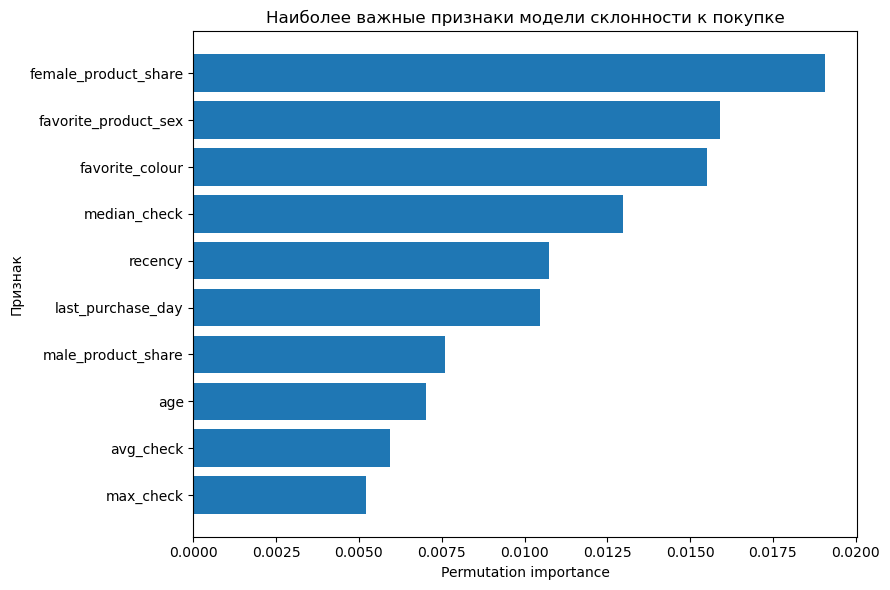

In [226]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(10).sort_values(
    "importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Permutation importance")
plt.ylabel("Признак")
plt.title(
    "Наиболее важные признаки модели склонности к покупке"
)

plt.tight_layout()

### Вывод по важности признаков

Наибольший вклад в прогноз склонности клиента к покупке внесли характеристики предыдущего покупательского поведения.

Наиболее значимыми оказались доля покупок женских товаров, предпочитаемый тип товара по полу и любимый цвет. Также заметное влияние имеют медианный чек, давность последней покупки и день последней покупки.

Это показывает, что вероятность покупки целевого товара в большей степени связана с предыдущим покупательским поведением и предпочтениями клиента, чем с отдельными социально-демографическими признаками.

Полученные результаты можно использовать для более точного отбора аудитории маркетинговой кампании и персонализации коммуникации.

## Итог по модели склонности к покупке

Для прогнозирования склонности клиентов города 1188 к покупке целевого товара были протестированы две модели: Logistic Regression и Random Forest.

В качестве итоговой модели выбран Random Forest, поскольку он показал более высокое качество ранжирования клиентов:

- ROC-AUC: 0.8863;
- PR-AUC: 0.0643;
- Lift в Top 5% аудитории: 7.52;
- Lift в Top 10% аудитории: 5.62;
- Lift в Top 20% аудитории: 4.06.

При выборе 5% клиентов с наиболее высокой прогнозируемой склонностью к покупке в этот сегмент попало 37.5% всех фактических покупателей тестовой выборки.

При расширении сегмента до 20% аудитории модель позволила охватить 81.25% фактических покупателей.

Таким образом, модель целесообразно использовать не как жёсткий классификатор «купит / не купит», а как инструмент ранжирования клиентов по вероятности покупки.

Для маркетинговой кампании рекомендуется в первую очередь работать с клиентами из верхних 5–20% рейтинга склонности в зависимости от доступного бюджета и стоимости коммуникации.

Наиболее значимыми для модели оказались признаки предыдущего покупательского поведения и предпочтений клиента: доля покупок женских товаров, предпочитаемый тип товара по полу, любимый цвет, медианный чек и показатели давности последней покупки.

Следует учитывать, что положительный класс представлен небольшим количеством наблюдений, поэтому полученные метрики необходимо интерпретировать с осторожностью и по возможности дополнительно проверять модель на новых данных.

# Итоговые выводы и рекомендации

В рамках проекта были проанализированы данные о клиентах и их покупках с целью оценки маркетинговых активностей, сегментации аудитории и поиска способов повышения эффективности будущих кампаний.

## 1. Подготовка данных

Данные из нескольких источников были объединены в единую аналитическую структуру. Были обработаны пропущенные значения, приведены к единому виду текстовые признаки, очищены названия товаров и информация о цветах.

В соответствии с условиями задачи дальнейший анализ проводился для клиентов страны 32.

Подготовленный датасет был использован для всех последующих этапов анализа и моделирования.

## 2. Восстановление пропущенного пола клиентов

Для клиентов, у которых информация о поле была утеряна, была построена модель бинарной классификации.

Модель позволила восстановить недостающие значения пола на основе доступных характеристик клиентов и сформировать более полный набор данных для дальнейшего анализа.

## 3. Анализ первой маркетинговой кампании

Эффективность первой маркетинговой кампании была оценена с помощью A/B-тестирования.

Были сопоставлены клиенты, которым предоставлялась персональная скидка, и контрольная группа со схожими характеристиками.

На основании рассчитанных метрик и статистических тестов была сформулирована бизнес-рекомендация по дальнейшему использованию данного механизма продвижения.

## 4. Сегментация клиентской базы

Для исследования структуры клиентской базы была проведена кластеризация.

Оптимальным было выбрано разделение аудитории на 6 кластеров. Для каждого сегмента были проанализированы покупательская активность, средние чеки, предпочтения по товарам и отношение к скидкам.

Полученные кластеры позволяют отказаться от одинакового подхода ко всей клиентской базе и использовать различные маркетинговые механики для разных типов покупателей.

## 5. Модель склонности к покупке

Для жителей города 1188 была построена модель склонности к покупке целевого товара.

Чтобы избежать утечки данных, признаки клиентов рассчитывались только по историческому периоду 0-44 дня, а целевая переменная формировалась по покупкам в последующем периоде 45-58 дней.

Были протестированы Logistic Regression и Random Forest. Лучшее качество показал Random Forest:

- ROC-AUC - 0.8863;
- PR-AUC - 0.0643;
- Lift в Top 5% - 7.52;
- Lift в Top 10% - 5.62;
- Lift в Top 20% - 4.06.

При выборе только 5% клиентов с максимальной прогнозируемой склонностью к покупке модель позволяет охватить 37.5% фактических покупателей тестовой выборки.

При работе с верхними 20% аудитории охватывается 81.25% фактических покупателей.

Поэтому модель рекомендуется использовать прежде всего для ранжирования клиентов и выбора наиболее перспективной аудитории для маркетинговых коммуникаций.

Наибольшее значение для прогнозирования имели характеристики предыдущего покупательского поведения и предпочтений клиента: доля покупок женских товаров, предпочитаемый тип товара по полу, любимый цвет, медианный чек и показатели давности последней покупки.

## Бизнес-рекомендации

Результаты проекта показывают, что маркетинговые коммуникации целесообразно делать более персонализированными.

Рекомендуется:

- учитывать результаты A/B-тестирования при принятии решений о масштабировании маркетинговых механик;
- использовать полученные клиентские кластеры для формирования различных предложений и коммуникаций;
- учитывать товарные предпочтения и историю покупок при выборе предложения для клиента;
- использовать модель склонности для ранжирования аудитории и направлять маркетинговый бюджет прежде всего на клиентов с наиболее высокой прогнозируемой вероятностью покупки;
- контролировать эффективность новых кампаний с помощью последующих A/B-тестов и регулярно переобучать модель на новых данных.

Таким образом, сочетание статистического анализа, сегментации и машинного обучения позволяет перейти от массовых маркетинговых коммуникаций к более точной работе с клиентскими сегментами и повысить потенциальную эффективность рекламных кампаний.